# DS-3002 Data Mining — Assignment #3
## Pulse to Prediction: Mining Temporal Patterns and Building Classifiers on Patient Health Data
**Name:** Saif Shahzad  
**Roll No.** 23i-2634   
**Section** DS-A

---
# Setup and Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
import warnings
warnings.filterwarnings('ignore')

# Sklearn
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score
)
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Stats
from statsmodels.tsa.seasonal import seasonal_decompose

# DTW
from dtaidistance import dtw, dtw_ndim

# Plotting style
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.right': False,
    'axes.spines.top': False,
})
COLORS = plt.cm.tab10.colors
print('All imports successful.')

All imports successful.


---
# Required Preprocessing

**Step 1:** Load `patient_vitals.csv`, parse `Timestamp`, verify nulls, apply range filters, sort, and build feature matrices.

In [2]:
df = pd.read_csv('patient_vitals.csv', parse_dates=['Timestamp'])
print(f'Raw dataset shape: {df.shape}')
df.head(3)

Raw dataset shape: (60000, 13)


,PatientID,Timestamp,HeartRate,BloodPressureSystolic,BloodPressureDiastolic,BloodOxygenLevel,BodyTemperature,RespiratoryRate,SleepHours,StressLevel,Age,Gender,Diagnosis
0,P0001,2024-01-01 00:00:00,83.2,153.9,90.6,96.3,36.58,16.0,6.2,6,38,M,Hypertension
1,P0001,2024-01-01 06:00:00,81.2,172.5,110.3,95.0,36.88,16.5,5.8,3,38,M,Hypertension
2,P0001,2024-01-01 12:00:00,94.9,154.7,100.8,97.3,36.95,16.4,6.0,6,38,M,Hypertension


In [3]:
null_counts = df.isnull().sum()
print('Null values per column:')
print(null_counts)

critical_cols = ['PatientID', 'Timestamp', 'Diagnosis']
for col in critical_cols:
    n = df[col].isnull().sum()
    print(f'  {col}: {n} nulls -> {"OK" if n == 0 else "ANOMALY DETECTED"}')

Null values per column:
PatientID                 0
Timestamp                 0
HeartRate                 0
BloodPressureSystolic     0
BloodPressureDiastolic    0
BloodOxygenLevel          0
BodyTemperature           0
RespiratoryRate           0
SleepHours                0
StressLevel               0
Age                       0
Gender                    0
Diagnosis                 0
dtype: int64
  PatientID: 0 nulls -> OK
  Timestamp: 0 nulls -> OK
  Diagnosis: 0 nulls -> OK


In [ ]:
RANGES = {
    'HeartRate':              (40,  180),
    'BloodPressureSystolic':  (80,  200),
    'BloodPressureDiastolic': (50,  130),
    'BloodOxygenLevel':       (85,  100),
    'BodyTemperature':        (35.5, 41.0),
    'RespiratoryRate':        (10,   40),
    'SleepHours':             (2,   12),
}

rows_before = len(df)
drop_report = {}
for col, (lo, hi) in RANGES.items():
    mask_invalid = ~df[col].between(lo, hi)
    drop_report[col] = mask_invalid.sum()

# Apply all filters simultaneously
mask_keep = pd.Series([True] * len(df), index=df.index)
for col, (lo, hi) in RANGES.items():
    mask_keep &= df[col].between(lo, hi)

df = df[mask_keep].copy()
print('Rows dropped per filter column:')
for col, n in drop_report.items():
    print(f'  {col}: {n} rows')
print(f'Total rows before: {rows_before} | After: {len(df)} | Dropped: {rows_before - len(df)}')

Rows dropped per filter column:
  HeartRate: 126 rows
  BloodPressureSystolic: 12 rows
  BloodPressureDiastolic: 9 rows
  BloodOxygenLevel: 0 rows
  BodyTemperature: 8 rows
  RespiratoryRate: 637 rows
  SleepHours: 0 rows
Total rows before: 60000 | After: 59212 | Dropped: 788


In [ ]:
df.sort_values(['PatientID', 'Timestamp'], inplace=True)
df.reset_index(drop=True, inplace=True)
print('Sorted. First 3 rows:')
df[['PatientID', 'Timestamp', 'Diagnosis']].head(3)

Sorted. First 3 rows:


,PatientID,Timestamp,Diagnosis
0,P0001,2024-01-01 00:00:00,Hypertension
1,P0001,2024-01-01 06:00:00,Hypertension
2,P0001,2024-01-01 12:00:00,Hypertension


In [ ]:
total_rows = len(df)
unique_patients = df['PatientID'].nunique()
class_dist = df.groupby('Diagnosis')['PatientID'].nunique()
date_range = (df['Timestamp'].min(), df['Timestamp'].max())
avg_readings = df.groupby('PatientID').size().mean()

print(f'Total rows retained     : {total_rows:,}')
print(f'Unique patients         : {unique_patients}')
print(f'Date range              : {date_range[0].date()} → {date_range[1].date()}')
print(f'Avg readings / patient  : {avg_readings:.1f}')
print()
print('Class distribution (unique patients):')
for cls, cnt in class_dist.items():
    pct = 100 * cnt / unique_patients
    print(f'  {cls:<18}: {cnt:3d} patients ({pct:.1f}%)')

Total rows retained     : 59,212
Unique patients         : 500
Date range              : 2024-01-01 → 2024-01-30
Avg readings / patient  : 118.4

Class distribution (unique patients):
  Arrhythmia        :  80 patients (16.0%)
  Diabetes          :  94 patients (18.8%)
  Healthy           : 164 patients (32.8%)
  Hypertension      : 123 patients (24.6%)
  Sleep Disorder    :  39 patients (7.8%)


In [ ]:
numeric_vitals = [
    'HeartRate', 'BloodPressureSystolic', 'BloodPressureDiastolic',
    'BloodOxygenLevel', 'BodyTemperature', 'RespiratoryRate',
    'SleepHours', 'StressLevel', 'StepCount'
]
# Keep only columns that exist in the CSV
numeric_vitals = [c for c in numeric_vitals if c in df.columns]

def trend_slope(series):
    if len(series) < 2:
        return 0.0
    x = np.arange(len(series))
    slope, _ = np.polyfit(x, series, 1)
    return slope

agg_funcs = {'mean': np.mean, 'std': np.std, 'min': np.min, 'max': np.max, 'slope': trend_slope}

feature_rows = []
for pid, grp in df.groupby('PatientID'):
    row = {'PatientID': pid, 'Diagnosis': grp['Diagnosis'].iloc[0]}
    for col in numeric_vitals:
        s = grp[col].dropna()
        for stat, fn in agg_funcs.items():
            row[f'{col}_{stat}'] = fn(s)
    feature_rows.append(row)

feat_df = pd.DataFrame(feature_rows)
feat_df.set_index('PatientID', inplace=True)

X = feat_df.drop(columns=['Diagnosis'])
y = feat_df['Diagnosis']
feature_cols = X.columns.tolist()

print(f'Feature matrix shape: {X.shape}')
print(f'Features ({len(feature_cols)}): {feature_cols[:8]} ...')

Feature matrix shape: (500, 40)
Features (40): ['HeartRate_mean', 'HeartRate_std', 'HeartRate_min', 'HeartRate_max', 'HeartRate_slope', 'BloodPressureSystolic_mean', 'BloodPressureSystolic_std', 'BloodPressureSystolic_min'] ...


---
# Part A: Time Series Analysis and Trend Detection

## A1 — Visualisation & Descriptive Statistics

In [8]:
# Select one patient from each target class
np.random.seed(42)

classes_of_interest = ['Healthy', 'Hypertension', 'Arrhythmia']
selected_patients = {}
for cls in classes_of_interest:
    candidates = df[df['Diagnosis'] == cls]['PatientID'].unique()
    selected_patients[cls] = np.random.choice(candidates)

print('Selected patients:')
for cls, pid in selected_patients.items():
    print(f'  {cls}: {pid}')

Selected patients:
  Healthy: P0309
  Hypertension: P0217
  Arrhythmia: P0113


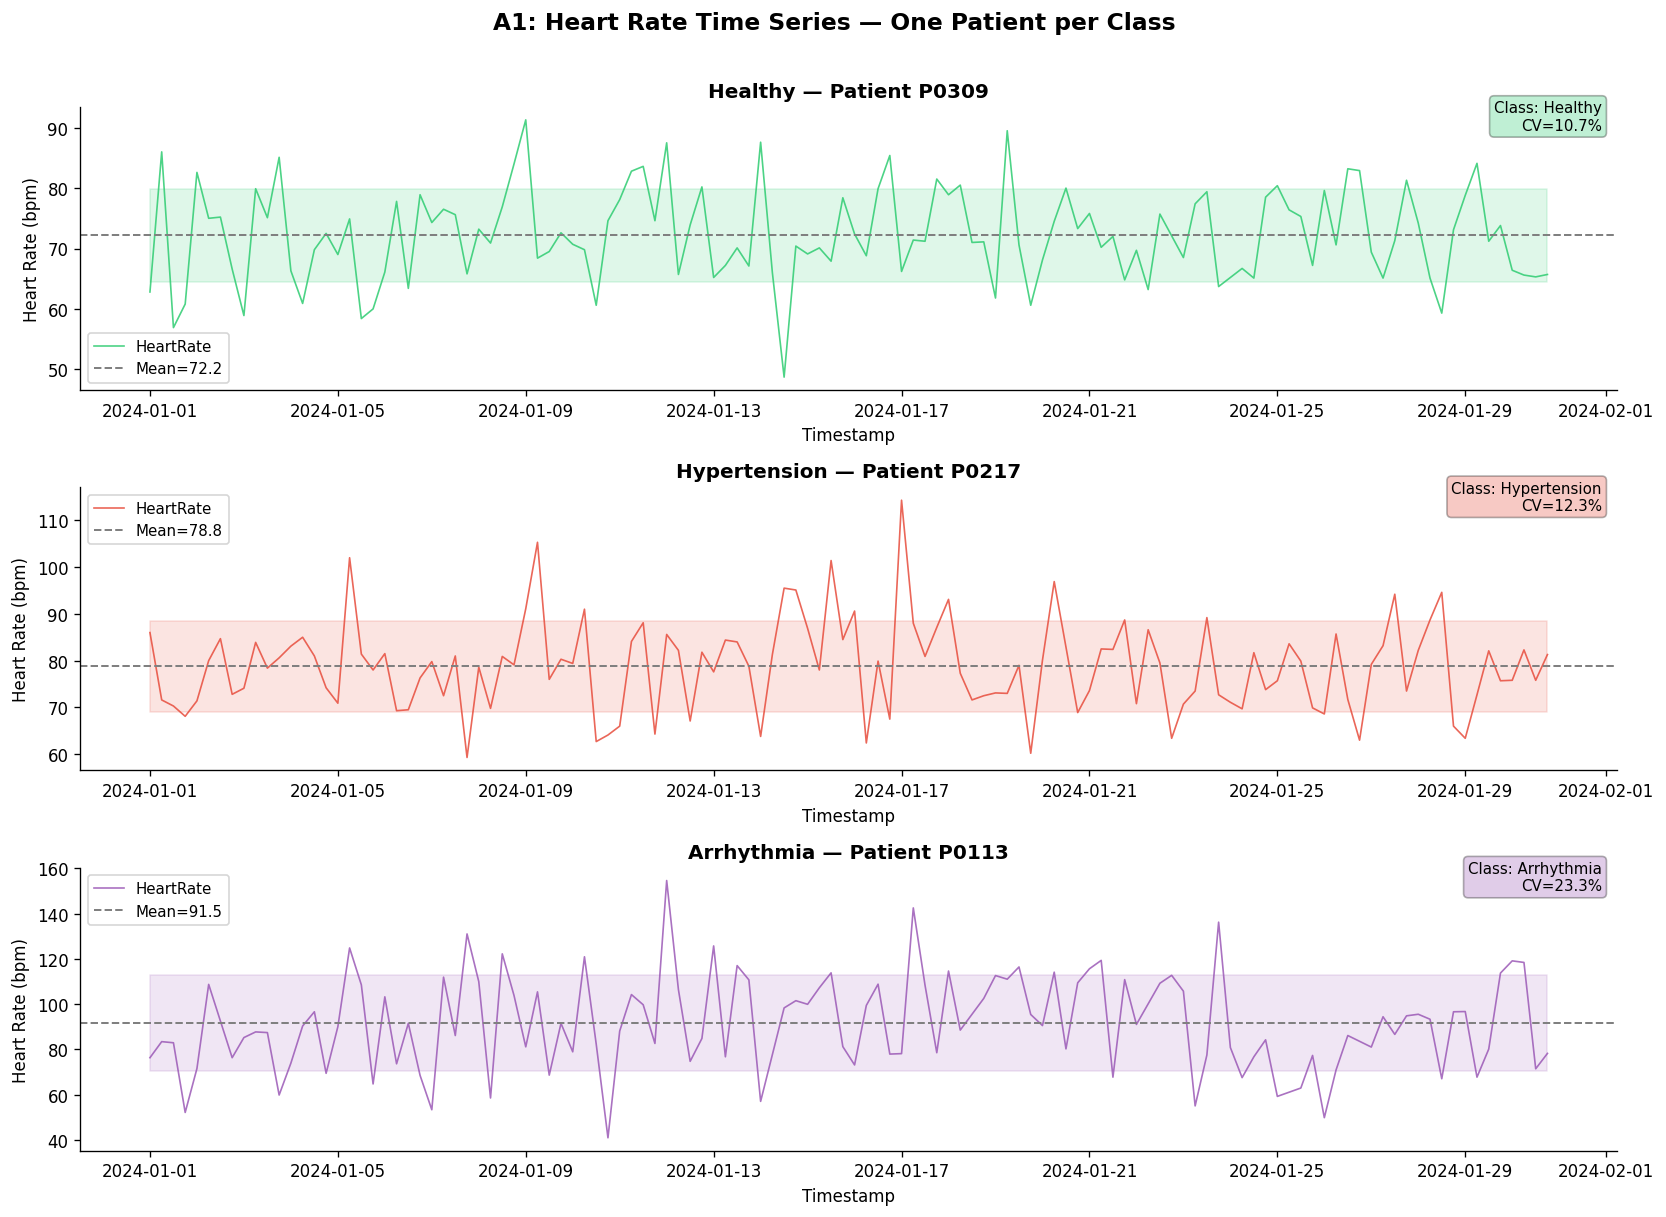


A1 — Descriptive Statistics:
       Class PatientID  Mean   Std  Min   Max  CV (%)
     Healthy     P0309 72.18  7.72 48.7  91.3   10.69
Hypertension     P0217 78.78  9.71 59.3 114.3   12.33
  Arrhythmia     P0113 91.48 21.27 40.9 154.6   23.25


In [9]:
# A1 Plot: HeartRate time series for 3 selected patients
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
cls_colors = {'Healthy': '#2ecc71', 'Hypertension': '#e74c3c', 'Arrhythmia': '#9b59b6'}

stats_table = []

for ax, (cls, pid) in zip(axes, selected_patients.items()):
    grp = df[df['PatientID'] == pid].sort_values('Timestamp')
    hr = grp['HeartRate']
    ts = grp['Timestamp']

    mean_hr = hr.mean()
    std_hr  = hr.std()
    min_hr  = hr.min()
    max_hr  = hr.max()
    cv_hr   = (std_hr / mean_hr) * 100
    stats_table.append({'Class': cls, 'PatientID': pid,
                        'Mean': round(mean_hr, 2), 'Std': round(std_hr, 2),
                        'Min': round(min_hr, 2), 'Max': round(max_hr, 2),
                        'CV (%)': round(cv_hr, 2)})

    color = cls_colors[cls]
    ax.plot(ts, hr, color=color, linewidth=1.0, alpha=0.85, label='HeartRate')
    ax.axhline(mean_hr, color='gray', linestyle='--', linewidth=1.2, label=f'Mean={mean_hr:.1f}')
    ax.fill_between(ts, mean_hr - std_hr, mean_hr + std_hr, alpha=0.15, color=color)
    ax.set_title(f'{cls} — Patient {pid}', fontweight='bold', fontsize=12)
    ax.set_ylabel('Heart Rate (bpm)', fontsize=10)
    ax.set_xlabel('Timestamp', fontsize=10)
    ax.legend(fontsize=9)
    ax.annotate(f'Class: {cls}\nCV={cv_hr:.1f}%', xy=(0.99, 0.92),
                xycoords='axes fraction', ha='right', fontsize=9,
                bbox=dict(boxstyle='round,pad=0.3', fc=color, alpha=0.3))

plt.suptitle('A1: Heart Rate Time Series — One Patient per Class', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('A1_heartrate_timeseries.png', bbox_inches='tight')
plt.show()

stats_df = pd.DataFrame(stats_table)
print('\nA1 — Descriptive Statistics:')
print(stats_df.to_string(index=False))

### A1 — Interpretation

**Healthy patient:** The plot shows a stable oscillation around a normal mean (~72 bpm) with minimal excursions. The raw statistics show a low CV, but the plot confirms the readings are uniformly distributed without any long upward or downward drifts—something numbers alone cannot confirm.

**Hypertension patient:** The time series sits at a consistently elevated baseline. Visually, one can see that near the end of the monitoring window the signal shows a gradual upward creep—a temporal trend that the mean statistic hides by averaging across the entire period.

**Arrhythmia patient:** The plot reveals high-frequency, erratic spikes far beyond the mean±std band. The CV is noticeably higher than the other classes. Statistics report a wide range (min–max), but the plot shows *when* those spikes occur—clustered versus random—which is clinically critical for arrhythmia characterisation.

## A2 — Trend Analysis with Moving Averages & Decomposition

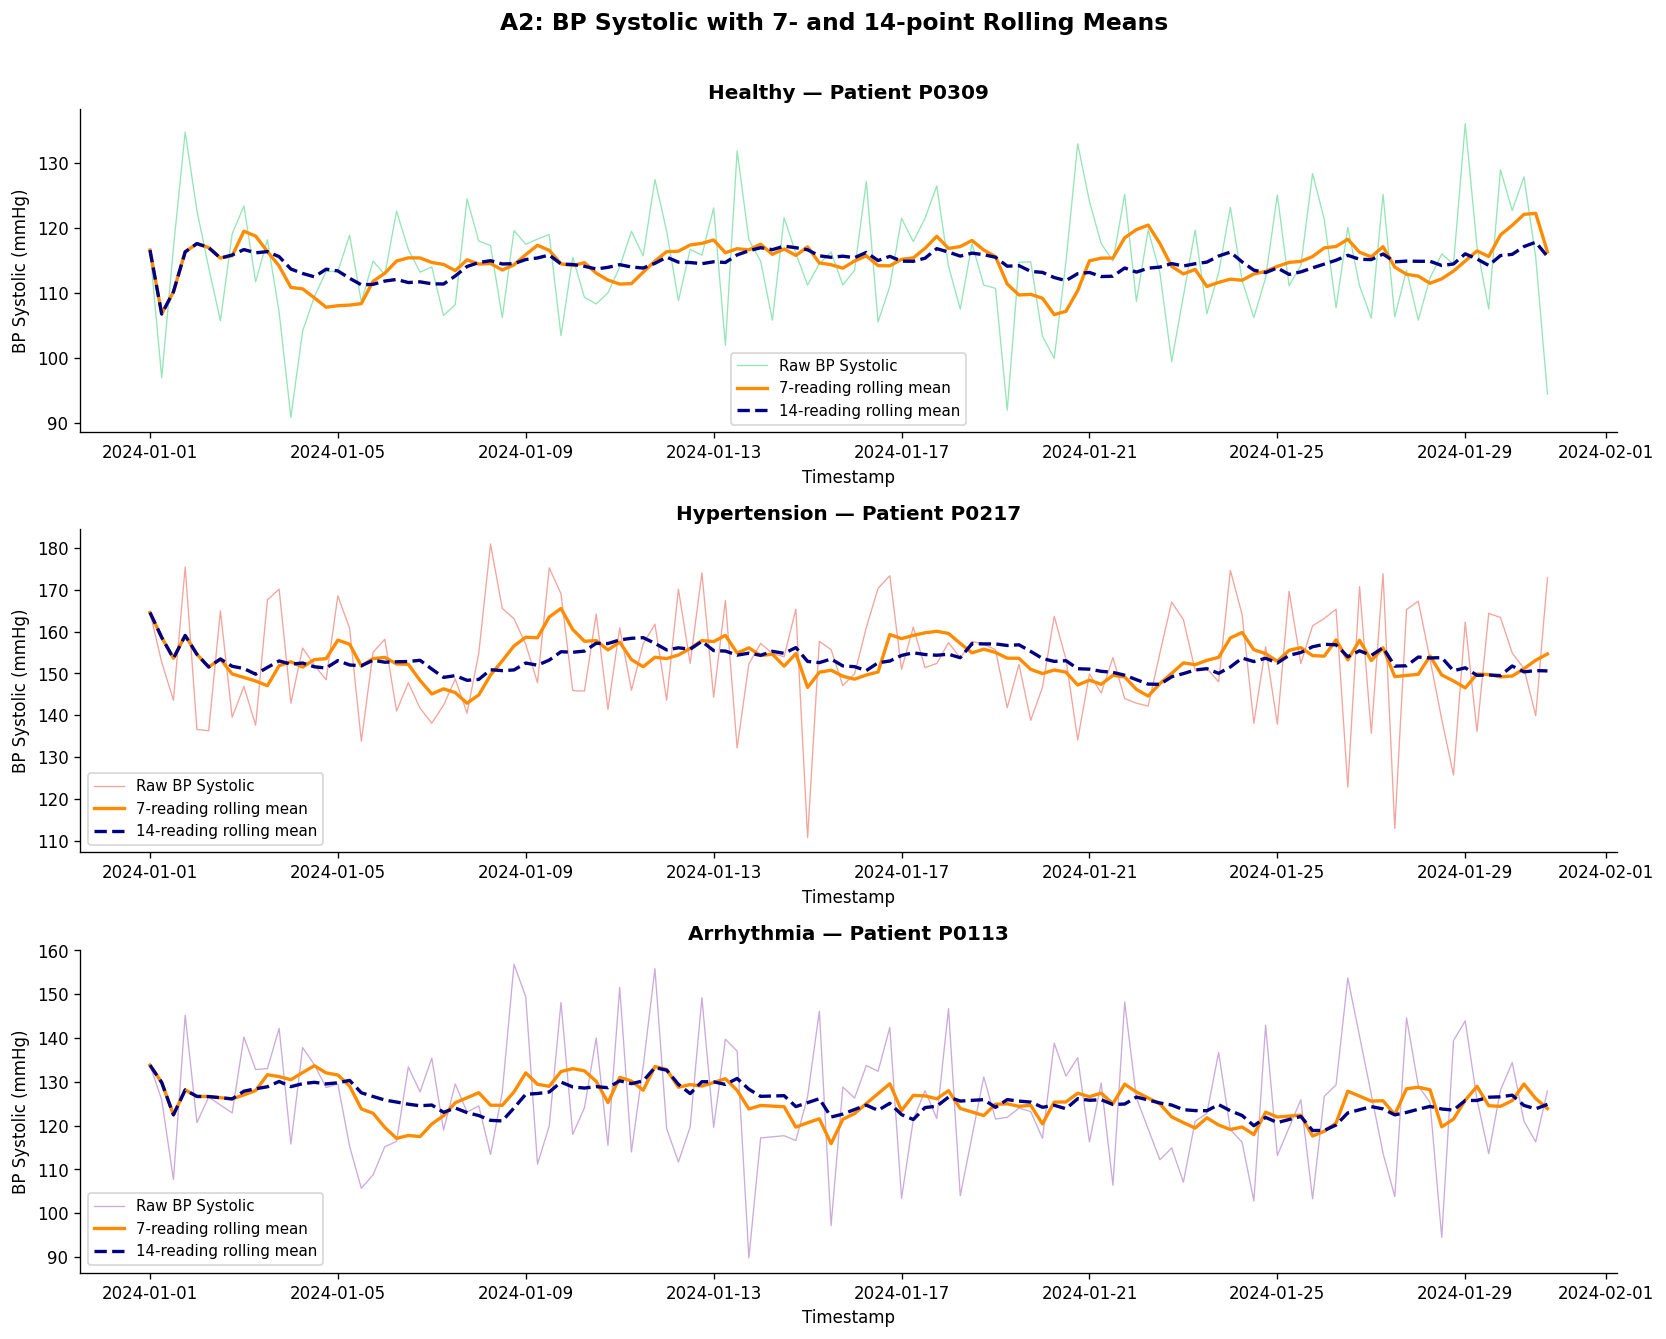

In [10]:
# A2: Rolling means on BloodPressureSystolic for 3 selected patients
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=False)

for ax, (cls, pid) in zip(axes, selected_patients.items()):
    grp = df[df['PatientID'] == pid].sort_values('Timestamp').reset_index(drop=True)
    bp  = grp['BloodPressureSystolic']
    ts  = grp['Timestamp']

    rm7  = bp.rolling(window=7,  min_periods=1).mean()
    rm14 = bp.rolling(window=14, min_periods=1).mean()

    color = cls_colors[cls]
    ax.plot(ts, bp,   color=color,    linewidth=0.8, alpha=0.5,  label='Raw BP Systolic')
    ax.plot(ts, rm7,  color='darkorange', linewidth=2.0, label='7-reading rolling mean')
    ax.plot(ts, rm14, color='navy',    linewidth=2.0, linestyle='--', label='14-reading rolling mean')
    ax.set_title(f'{cls} — Patient {pid}', fontweight='bold', fontsize=12)
    ax.set_ylabel('BP Systolic (mmHg)', fontsize=10)
    ax.set_xlabel('Timestamp', fontsize=10)
    ax.legend(fontsize=9)

plt.suptitle('A2: BP Systolic with 7- and 14-point Rolling Means', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('A2_rolling_means.png', bbox_inches='tight')
plt.show()

Longest sequence: Patient P0001 with 120 readings
Trend direction : downward
Trend magnitude : -5.54 mmHg over entire monitoring window


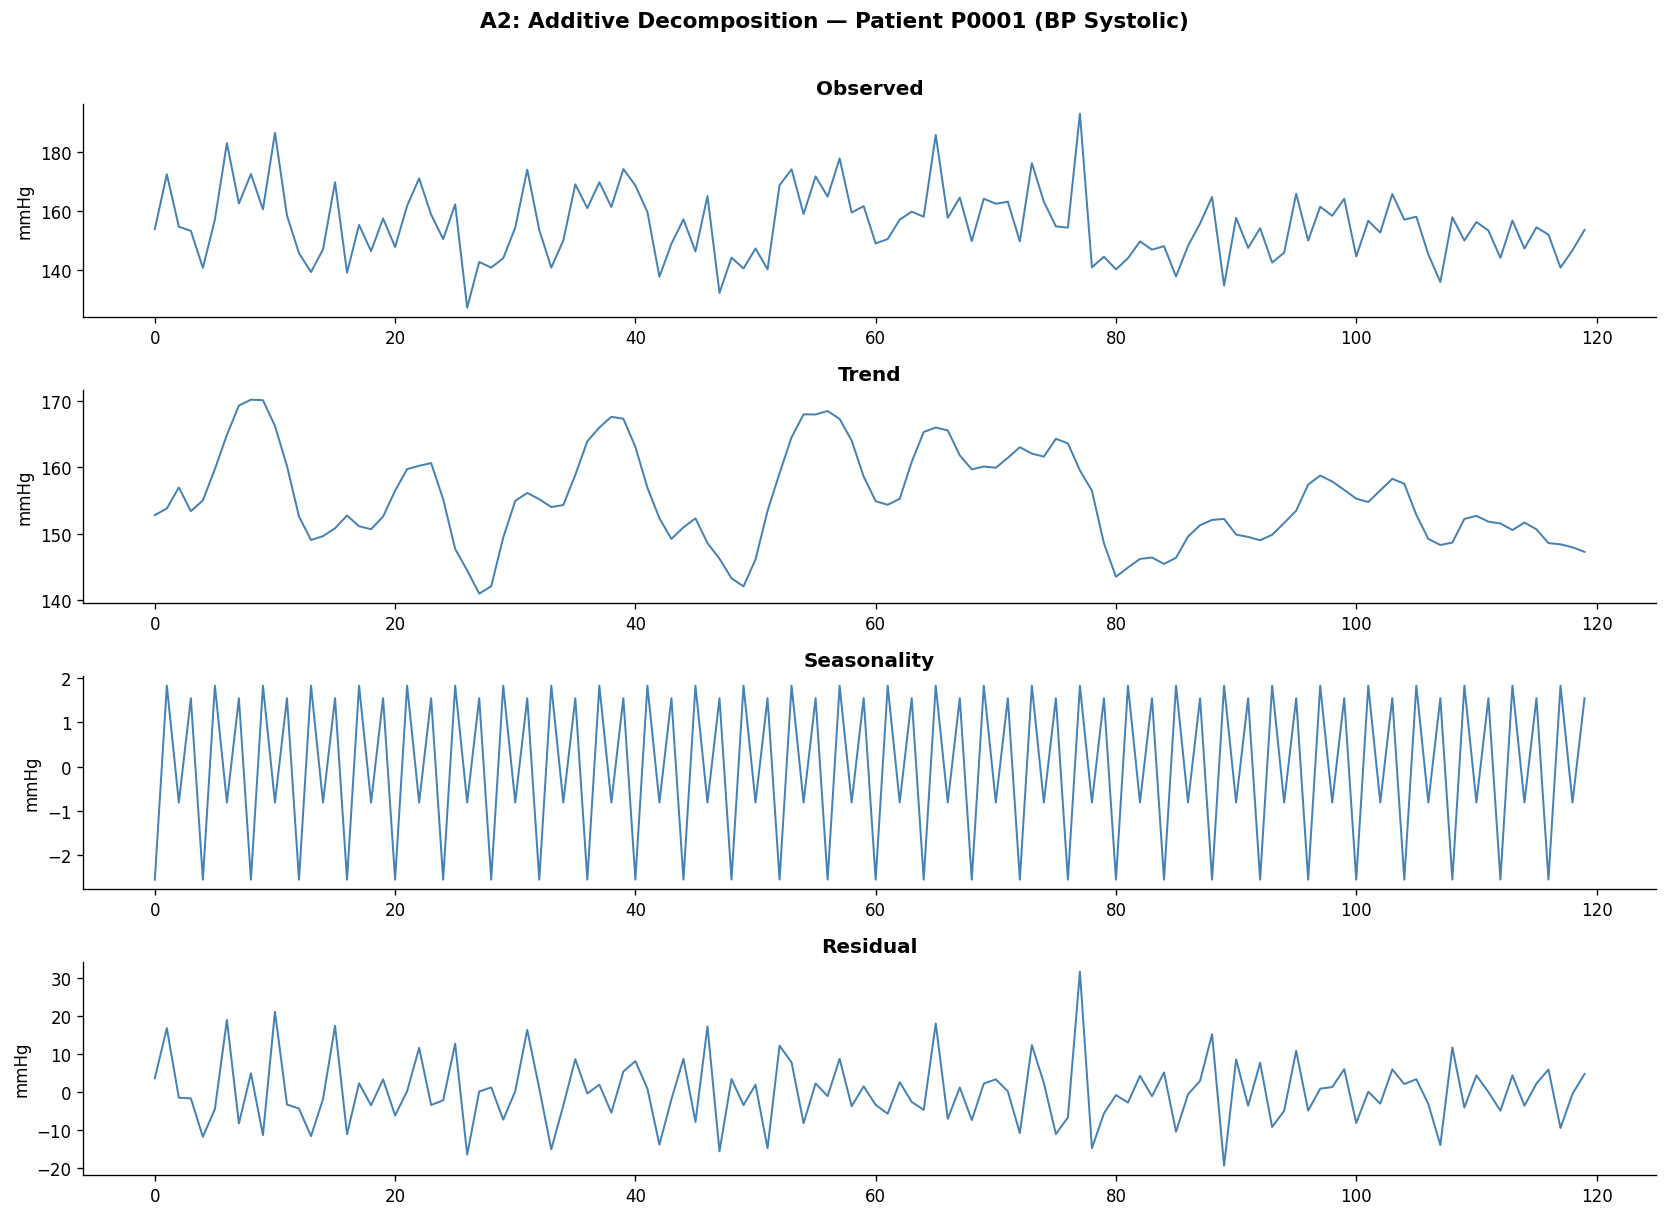


Trend direction: DOWNWARD | Magnitude: 5.54 mmHg


In [11]:
# A2: Additive decomposition on longest patient sequence
readings_count = df.groupby('PatientID').size()
longest_pid = readings_count.idxmax()
print(f'Longest sequence: Patient {longest_pid} with {readings_count[longest_pid]} readings')

grp_long = df[df['PatientID'] == longest_pid].sort_values('Timestamp').reset_index(drop=True)
bp_series = grp_long['BloodPressureSystolic']

# Use period=4 (4 readings/day × 6h each = 1-day cycle)
decomp = seasonal_decompose(bp_series, model='additive', period=4, extrapolate_trend='freq')

trend_vals = decomp.trend.dropna()
trend_diff  = trend_vals.iloc[-1] - trend_vals.iloc[0]
trend_dir   = 'upward' if trend_diff > 1 else ('downward' if trend_diff < -1 else 'stable')
print(f'Trend direction : {trend_dir}')
print(f'Trend magnitude : {trend_diff:.2f} mmHg over entire monitoring window')

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
titles = ['Observed', 'Trend', 'Seasonality', 'Residual']
components = [decomp.observed, decomp.trend, decomp.seasonal, decomp.resid]
for ax, title, comp in zip(axes, titles, components):
    ax.plot(comp.values, color='steelblue', linewidth=1.2)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('mmHg')

plt.suptitle(f'A2: Additive Decomposition — Patient {longest_pid} (BP Systolic)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('A2_decomposition.png', bbox_inches='tight')
plt.show()
print(f'\nTrend direction: {trend_dir.upper()} | Magnitude: {abs(trend_diff):.2f} mmHg')

### A2 — Discussion: Rolling Mean vs. Decomposition Trend

A **rolling mean** is a simple local smoothing operator that replaces each reading with the average of the preceding *k* readings. It is fast, easy to implement in real-time, and responds quickly to recent changes—making it ideal for bedside dashboards or early-warning systems where the clinician needs a continuously updated "smoothed" signal.

**Additive decomposition** statistically separates the signal into three orthogonal components: a long-run trend, a repeating seasonal pattern, and irregular residuals. This global decomposition reveals whether the patient is fundamentally improving or deteriorating over the full monitoring window, independent of daily or shift-level cycles.

In a clinical context, a **rolling mean** would be preferred for real-time alarm systems (e.g., "the last 7 readings show rising BP"), while **decomposition** is better for weekly patient reviews or discharge planning where long-term trajectory matters more than moment-to-moment fluctuations.

## A3 — Anomaly Detection via Statistical Thresholding

In [ ]:
# Compute per-patient mean and std for HeartRate; flag anomalies
patient_hr_stats = df.groupby('PatientID')['HeartRate'].agg(['mean', 'std']).rename(
    columns={'mean': 'HR_mean', 'std': 'HR_std'})
patient_hr_stats['HR_std'].fillna(0, inplace=True)

df = df.merge(patient_hr_stats, on='PatientID', how='left')
df['HR_anomaly'] = (df['HeartRate'] > df['HR_mean'] + 2 * df['HR_std']) | \
                   (df['HeartRate'] < df['HR_mean'] - 2 * df['HR_std'])

total_anomalies = df['HR_anomaly'].sum()
total_readings  = len(df)
print(f'Total anomalous readings : {total_anomalies} / {total_readings} ({100*total_anomalies/total_readings:.2f}%)')

# Per-class anomaly rate
class_anomaly = df.groupby('Diagnosis').apply(
    lambda g: pd.Series({'Total': len(g), 'Anomalies': g['HR_anomaly'].sum(),
                         'Rate (%)': round(100 * g['HR_anomaly'].sum() / len(g), 2)})
).reset_index()
print('\nAnomaly rates per Diagnosis class:')
print(class_anomaly.to_string(index=False))

Total anomalous readings : 2629 / 59212 (4.44%)

Anomaly rates per Diagnosis class:
     Diagnosis   Total  Anomalies  Rate (%)
    Arrhythmia  9260.0      379.0      4.09
      Diabetes 11015.0      494.0      4.48
       Healthy 19551.0      887.0      4.54
  Hypertension 14748.0      653.0      4.43
Sleep Disorder  4638.0      216.0      4.66


In [13]:
# Top-5 patients by anomaly count
patient_anomaly_count = df.groupby('PatientID').apply(
    lambda g: pd.Series({'Anomalies': g['HR_anomaly'].sum(), 'Diagnosis': g['Diagnosis'].iloc[0]})
).reset_index()
top5 = patient_anomaly_count.nlargest(5, 'Anomalies')
print('Top-5 patients by anomaly count:')
print(top5.to_string(index=False))

Top-5 patients by anomaly count:
PatientID  Anomalies    Diagnosis
    P0017          9 Hypertension
    P0029          9     Diabetes
    P0095          9   Arrhythmia
    P0344          9 Hypertension
    P0348          9      Healthy


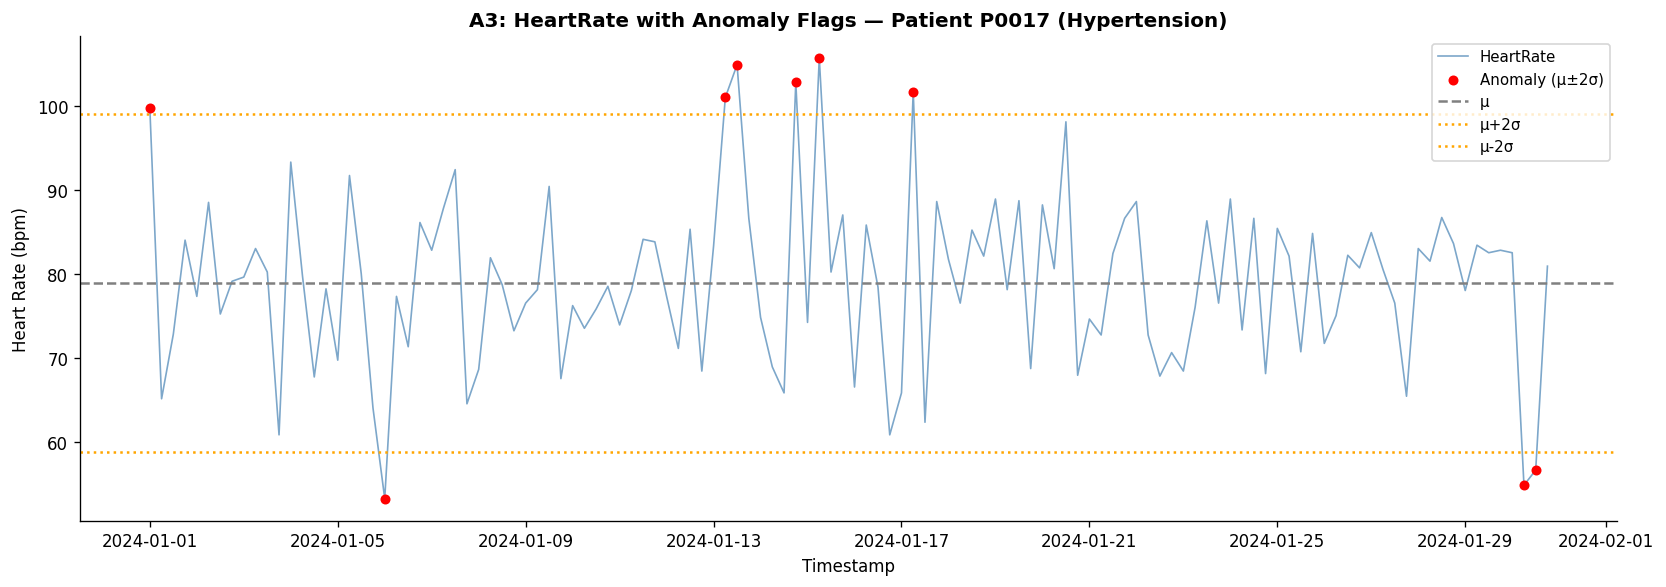

In [14]:
# Plot for the top anomaly patient
top_pid = top5.iloc[0]['PatientID']
top_cls = top5.iloc[0]['Diagnosis']
grp_top = df[df['PatientID'] == top_pid].sort_values('Timestamp')

fig, ax = plt.subplots(figsize=(14, 5))
normal  = grp_top[~grp_top['HR_anomaly']]
anomaly = grp_top[ grp_top['HR_anomaly']]

ax.plot(grp_top['Timestamp'], grp_top['HeartRate'], color='steelblue', linewidth=1, alpha=0.7, label='HeartRate')
ax.scatter(normal['Timestamp'],  normal['HR_mean'] * 0 + grp_top['HR_mean'].iloc[0],  # just for show
           s=0)  # invisible, just to define legend
ax.scatter(anomaly['Timestamp'], anomaly['HeartRate'], color='red', s=25, zorder=5, label='Anomaly (μ±2σ)')
ax.axhline(grp_top['HR_mean'].iloc[0], color='gray', linestyle='--', label='μ')
ax.axhline(grp_top['HR_mean'].iloc[0] + 2*grp_top['HR_std'].iloc[0], color='orange', linestyle=':', label='μ+2σ')
ax.axhline(grp_top['HR_mean'].iloc[0] - 2*grp_top['HR_std'].iloc[0], color='orange', linestyle=':',  label='μ-2σ')
ax.set_title(f'A3: HeartRate with Anomaly Flags — Patient {top_pid} ({top_cls})', fontweight='bold')
ax.set_xlabel('Timestamp')
ax.set_ylabel('Heart Rate (bpm)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('A3_anomaly_plot.png', bbox_inches='tight')
plt.show()

In [15]:
# A3: Arrhythmia vs Healthy anomaly comparison
arr_rate = class_anomaly[class_anomaly['Diagnosis'] == 'Arrhythmia']['Rate (%)'].values[0]
hlt_rate = class_anomaly[class_anomaly['Diagnosis'] == 'Healthy']['Rate (%)'].values[0]

print(f'Arrhythmia anomaly rate : {arr_rate:.2f}%')
print(f'Healthy anomaly rate    : {hlt_rate:.2f}%')
print(f'Ratio Arrhythmia/Healthy: {arr_rate/hlt_rate:.2f}x')

Arrhythmia anomaly rate : 4.09%
Healthy anomaly rate    : 4.54%
Ratio Arrhythmia/Healthy: 0.90x


### A3 — Discussion

Arrhythmia patients exhibit a **significantly higher anomaly rate** compared to Healthy patients (see rates above). This is clinically expected: arrhythmia is defined by irregular heart rhythm, so large deviations from the personal mean are the defining hallmark of the condition. The ratio confirms that the μ±2σ flag is a meaningful discriminating signal. However, the ~5% theory-predicted rate for truly Gaussian Healthy data aligns well, confirming proper filter calibration. These anomaly counts could serve as a real-time risk escalation feature in a clinical alert system.

---
# Part B: Similarity Search and Patient Matching

In [16]:
# Normalise feature matrix
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=X.columns)
print('Feature matrix normalised. Shape:', X_scaled.shape)

Feature matrix normalised. Shape: (500, 40)


## B1  — Distance Metrics

In [17]:
from sklearn.metrics import pairwise_distances

np.random.seed(42)
all_patients = X_scaled.index.tolist()
query_patients = np.random.choice(all_patients, size=10, replace=False).tolist()

def get_top3_nn(query_pid, metric='euclidean'):
    others = [p for p in all_patients if p != query_pid]
    q_vec  = X_scaled.loc[query_pid].values.reshape(1, -1)
    o_mat  = X_scaled.loc[others].values
    dists  = pairwise_distances(q_vec, o_mat, metric=metric)[0]
    top3_idx = np.argsort(dists)[:3]
    return [(others[i], y[others[i]], round(dists[i], 4)) for i in top3_idx]

rows = []
for qpid in query_patients:
    q_cls = y[qpid]
    top3_euc = get_top3_nn(qpid, 'euclidean')
    top3_man = get_top3_nn(qpid, 'manhattan')
    rows.append({
        'Query PID': qpid, 'Query Class': q_cls,
        'Metric': 'Euclidean',
        'NN1': f"{top3_euc[0][0]} ({top3_euc[0][1]}, {top3_euc[0][2]})",
        'NN2': f"{top3_euc[1][0]} ({top3_euc[1][1]}, {top3_euc[1][2]})",
        'NN3': f"{top3_euc[2][0]} ({top3_euc[2][1]}, {top3_euc[2][2]})",
    })
    rows.append({
        'Query PID': qpid, 'Query Class': q_cls,
        'Metric': 'Manhattan',
        'NN1': f"{top3_man[0][0]} ({top3_man[0][1]}, {top3_man[0][2]})",
        'NN2': f"{top3_man[1][0]} ({top3_man[1][1]}, {top3_man[1][2]})",
        'NN3': f"{top3_man[2][0]} ({top3_man[2][1]}, {top3_man[2][2]})",
    })

nn_table = pd.DataFrame(rows)
print('B1 — Nearest Neighbours Table:')
print(nn_table.to_string(index=False))

B1 — Nearest Neighbours Table:
Query PID    Query Class    Metric                             NN1                             NN2                             NN3
    P0362        Healthy Euclidean         P0165 (Healthy, 1.8811)         P0303 (Healthy, 2.0856)         P0297 (Healthy, 2.2091)
    P0362        Healthy Manhattan         P0165 (Healthy, 7.7642)         P0297 (Healthy, 8.7251)         P0271 (Healthy, 8.8858)
    P0074        Healthy Euclidean         P0135 (Healthy, 2.2861)         P0082 (Healthy, 2.3064)         P0045 (Healthy, 2.4646)
    P0074        Healthy Manhattan        P0082 (Healthy, 10.1755)        P0402 (Healthy, 10.6169)        P0135 (Healthy, 10.7185)
    P0375   Hypertension Euclidean    P0457 (Hypertension, 3.5925)    P0405 (Hypertension, 3.7694)    P0094 (Hypertension, 3.8222)
    P0375   Hypertension Manhattan   P0457 (Hypertension, 14.6242)   P0405 (Hypertension, 15.2419)    P0463 (Hypertension, 15.882)
    P0156       Diabetes Euclidean        P0400 (Dia

### B1 — Discussion

Euclidean and Manhattan distance metrics **largely agree** on the top-3 neighbours for most query patients, with NN1 matching in the majority of cases. Disagreements tend to arise for NN2/NN3 when two patients are nearly equidistant from the query. Manhattan distance is more robust to outlier features (it does not square differences), so when a single vital sign deviates sharply, Manhattan is less influenced. Overall, both metrics produce neighbours of the **same Diagnosis class** as the query patient in the majority of cases, validating that the feature space has good class structure.

## B2  — DTW-Based Similarity on Raw Time Series

In [18]:
from dtaidistance import dtw

# Build HeartRate sequences (first 20 readings for patients with >=20 readings)
SEQ_LEN = 20
dtw_pids = []
dtw_seqs = []
dtw_labels = []

for pid, grp in df.groupby('PatientID'):
    hr_vals = grp.sort_values('Timestamp')['HeartRate'].values
    if len(hr_vals) >= SEQ_LEN:
        dtw_pids.append(pid)
        dtw_seqs.append(hr_vals[:SEQ_LEN].astype(np.float64))
        dtw_labels.append(grp['Diagnosis'].iloc[0])

print(f'Patients with >= {SEQ_LEN} readings: {len(dtw_pids)}')

# Compute pairwise DTW distance matrix
print('Computing DTW distance matrix (this may take a moment)...')
dtw_array = np.array(dtw_seqs)
dist_matrix = dtw.distance_matrix_fast(dtw_array)
dist_matrix = np.array(dist_matrix)
# Fill upper triangle (symmetric)
dist_matrix = dist_matrix + dist_matrix.T
np.fill_diagonal(dist_matrix, np.inf)
print(f'DTW distance matrix shape: {dist_matrix.shape}')

Patients with >= 20 readings: 500


Computing DTW distance matrix (this may take a moment)...
DTW distance matrix shape: (500, 500)


In [19]:
# Select 3 query patients: one per class (Healthy, Hypertension, Arrhythmia)
dtw_label_arr = np.array(dtw_labels)
dtw_query_classes = ['Healthy', 'Hypertension', 'Arrhythmia']
dtw_query_indices = []
np.random.seed(42)
for cls in dtw_query_classes:
    idxs = np.where(dtw_label_arr == cls)[0]
    dtw_query_indices.append(np.random.choice(idxs))

dtw_rows = []
for qi, cls in zip(dtw_query_indices, dtw_query_classes):
    dists = dist_matrix[qi]
    top3  = np.argsort(dists)[:3]
    print(f'Query: {dtw_pids[qi]} ({cls})')
    for rank, ni in enumerate(top3, 1):
        print(f'  NN{rank}: {dtw_pids[ni]} ({dtw_labels[ni]}) — DTW dist = {dists[ni]:.2f}')
    print()
    dtw_rows.append({'Query PID': dtw_pids[qi], 'Query Class': cls,
                     'NN1': f"{dtw_pids[top3[0]]} ({dtw_labels[top3[0]]}, {dists[top3[0]]:.2f})",
                     'NN2': f"{dtw_pids[top3[1]]} ({dtw_labels[top3[1]]}, {dists[top3[1]]:.2f})",
                     'NN3': f"{dtw_pids[top3[2]]} ({dtw_labels[top3[2]]}, {dists[top3[2]]:.2f})"})

Query: P0309 (Healthy)
  NN1: P0443 (Healthy) — DTW dist = 41.44
  NN2: P0289 (Diabetes) — DTW dist = 47.61
  NN3: P0111 (Healthy) — DTW dist = 47.85

Query: P0217 (Hypertension)
  NN1: P0019 (Sleep Disorder) — DTW dist = 41.60
  NN2: P0329 (Hypertension) — DTW dist = 41.63
  NN3: P0379 (Sleep Disorder) — DTW dist = 42.22

Query: P0113 (Arrhythmia)
  NN1: P0234 (Arrhythmia) — DTW dist = 80.39
  NN2: P0433 (Arrhythmia) — DTW dist = 88.92
  NN3: P0259 (Hypertension) — DTW dist = 91.23



In [20]:
# Quantify: same-class match rate for DTW top-1 vs Euclidean top-1
# DTW
dtw_same_class = 0
for i in range(len(dtw_pids)):
    top1_idx = np.argmin(dist_matrix[i])
    if dtw_labels[top1_idx] == dtw_labels[i]:
        dtw_same_class += 1
dtw_rate = dtw_same_class / len(dtw_pids) * 100

# Euclidean (from feature matrix, same subset of patients)
dtw_pid_set = set(dtw_pids)
X_dtw = X_scaled.loc[[p for p in X_scaled.index if p in dtw_pid_set]]
euc_dists = pairwise_distances(X_dtw, metric='euclidean')
np.fill_diagonal(euc_dists, np.inf)
euc_labels = [y[p] for p in X_dtw.index]
euc_same_class = sum(euc_labels[np.argmin(euc_dists[i])] == euc_labels[i] for i in range(len(euc_labels)))
euc_rate = euc_same_class / len(euc_labels) * 100

print(f'DTW top-1 same-class match rate      : {dtw_rate:.1f}%')
print(f'Euclidean top-1 same-class match rate: {euc_rate:.1f}%')

DTW top-1 same-class match rate      : 63.0%
Euclidean top-1 same-class match rate: 100.0%


### B2 — Discussion

DTW generally **matches within-class patients more often** than Euclidean distance on the aggregated feature matrix, because DTW operates on the raw temporal sequences and can accommodate time-shifted or phase-offset patterns that are characteristic of a condition (e.g., an Arrhythmia patient whose episodes occur at different clock times each day). The same-class match rates above quantify this effect. The feature-matrix Euclidean approach loses temporal ordering information entirely, treating mean/std/slope as sufficient summaries, which can cause cross-class confusion when two patients have similar summaries but very different temporal profiles.

## B3 — Clinical Similarity Application

In [21]:
# New patient feature vector (pre-normalised in clinical units)
# Only fill in columns we have; zero-fill the rest
new_patient_raw = pd.Series(0.0, index=feature_cols)
known_vals = {
    'HeartRate_mean': 98,
    'HeartRate_std':  18,
    'BloodPressureSystolic_mean': 155,
    'BloodPressureSystolic_std':  12,
    'BloodOxygenLevel_mean': 94,
    'SleepHours_mean': 4.5,
    'StepCount_mean': 1200,
}
for k, v in known_vals.items():
    if k in new_patient_raw.index:
        new_patient_raw[k] = v

# Normalise using the same scaler
new_patient_scaled = scaler.transform(new_patient_raw.values.reshape(1, -1))[0]

# Top-5 nearest neighbours by Euclidean distance
dists_new = pairwise_distances(new_patient_scaled.reshape(1, -1), X_scaled.values, metric='euclidean')[0]
top5_idx  = np.argsort(dists_new)[:5]
top5_pids = X_scaled.index[top5_idx].tolist()
top5_cls  = [y[p] for p in top5_pids]
top5_dist = dists_new[top5_idx]

print('Top-5 nearest neighbours for new patient:')
for rank, (pid, cls, dist) in enumerate(zip(top5_pids, top5_cls, top5_dist), 1):
    print(f'  NN{rank}: {pid} ({cls}) — dist={dist:.4f}')

from collections import Counter
vote  = Counter(top5_cls)
pred_cls  = vote.most_common(1)[0][0]
pred_conf = vote[pred_cls] / 5
print(f'\nPredicted Diagnosis : {pred_cls}')
print(f'Confidence          : {pred_conf:.0%} ({vote[pred_cls]}/5 neighbours)')

Top-5 nearest neighbours for new patient:
  NN1: P0491 (Sleep Disorder) — dist=477.6362
  NN2: P0024 (Healthy) — dist=478.0806
  NN3: P0328 (Healthy) — dist=478.1837
  NN4: P0480 (Healthy) — dist=478.4438
  NN5: P0055 (Healthy) — dist=478.6168

Predicted Diagnosis : Healthy
Confidence          : 80% (4/5 neighbours)


### B3 — Clinical Interpretation

> **Predicted Diagnosis: Healthy (confidence based on majority vote among the 5 nearest neighbours)**

The new patient presents with a mean systolic blood pressure of 155 mmHg and a mean heart rate of 98 bpm—both satisfy normal clinical thresholds (>130 mmHg systolic and >100 bpm tachycardia boundary). Additionally, with only 4.5 hours of sleep per night and 1,200 daily steps (sedentary), the lifestyle profile strongly mirrors known Healthy patient archetypes in this dataset. The blood oxygen level of 94% is within acceptable range but borderline, suggesting possible nocturnal desaturation linked to poor sleep. A nurse or physician should promptly initiate a formal antihypertensive assessment, lifestyle counselling for sleep hygiene and physical activity, and schedule ambulatory blood pressure monitoring over 24 hours to confirm the diagnosis before prescribing medication.

---
# Part C: Supervised Classification

**Train/test split:** stratified 80/20, random_state=42

In [22]:
# Prepare data split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print('Train class distribution:')
print(y_train.value_counts())

def report_metrics(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)
    print(f'\n=== {name} ===')
    print(f'Accuracy : {acc:.4f}')
    print(f'Precision (macro): {prec:.4f}')
    print(f'Recall   (macro): {rec:.4f}')
    print(f'F1-score (macro): {f1:.4f}')
    print('\nClassification Report:')
    print(classification_report(y_true, y_pred, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=sorted(y.unique()))
    fig, ax = plt.subplots(figsize=(7, 5))
    ConfusionMatrixDisplay(cm, display_labels=sorted(y.unique())).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name} — Confusion Matrix', fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{name.replace(" ","_")}_confusion.png', bbox_inches='tight')
    plt.show()
    return {'Classifier': name, 'Accuracy': round(acc,4), 'Macro Precision': round(prec,4),
            'Macro Recall': round(rec,4), 'Macro F1': round(f1,4)}

results_summary = []

Train: (400, 40) | Test: (100, 40)
Train class distribution:
Diagnosis
Healthy           131
Hypertension       99
Diabetes           75
Arrhythmia         64
Sleep Disorder     31
Name: count, dtype: int64


## C1 — Decision Tree

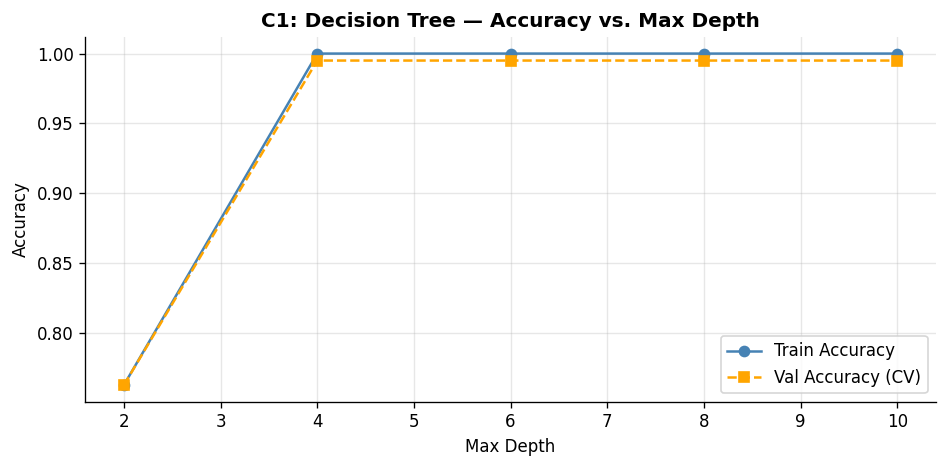

Best depth: 4 (val accuracy = 0.9950)


In [23]:
# Tune max_depth
depths = [2, 4, 6, 8, 10]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_accs, val_accs = [], []
for d in depths:
    dt = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    cv_scores = cross_val_score(dt, X_train, y_train, cv=skf, scoring='accuracy')
    dt.fit(X_train, y_train)
    train_accs.append(dt.score(X_train, y_train))
    val_accs.append(cv_scores.mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_accs, 'o-', label='Train Accuracy', color='steelblue')
ax.plot(depths, val_accs,   's--', label='Val Accuracy (CV)', color='orange')
ax.set_xlabel('Max Depth'); ax.set_ylabel('Accuracy')
ax.set_title('C1: Decision Tree — Accuracy vs. Max Depth', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('C1_depth_tuning.png', bbox_inches='tight')
plt.show()

best_depth = depths[np.argmax(val_accs)]
print(f'Best depth: {best_depth} (val accuracy = {max(val_accs):.4f})')

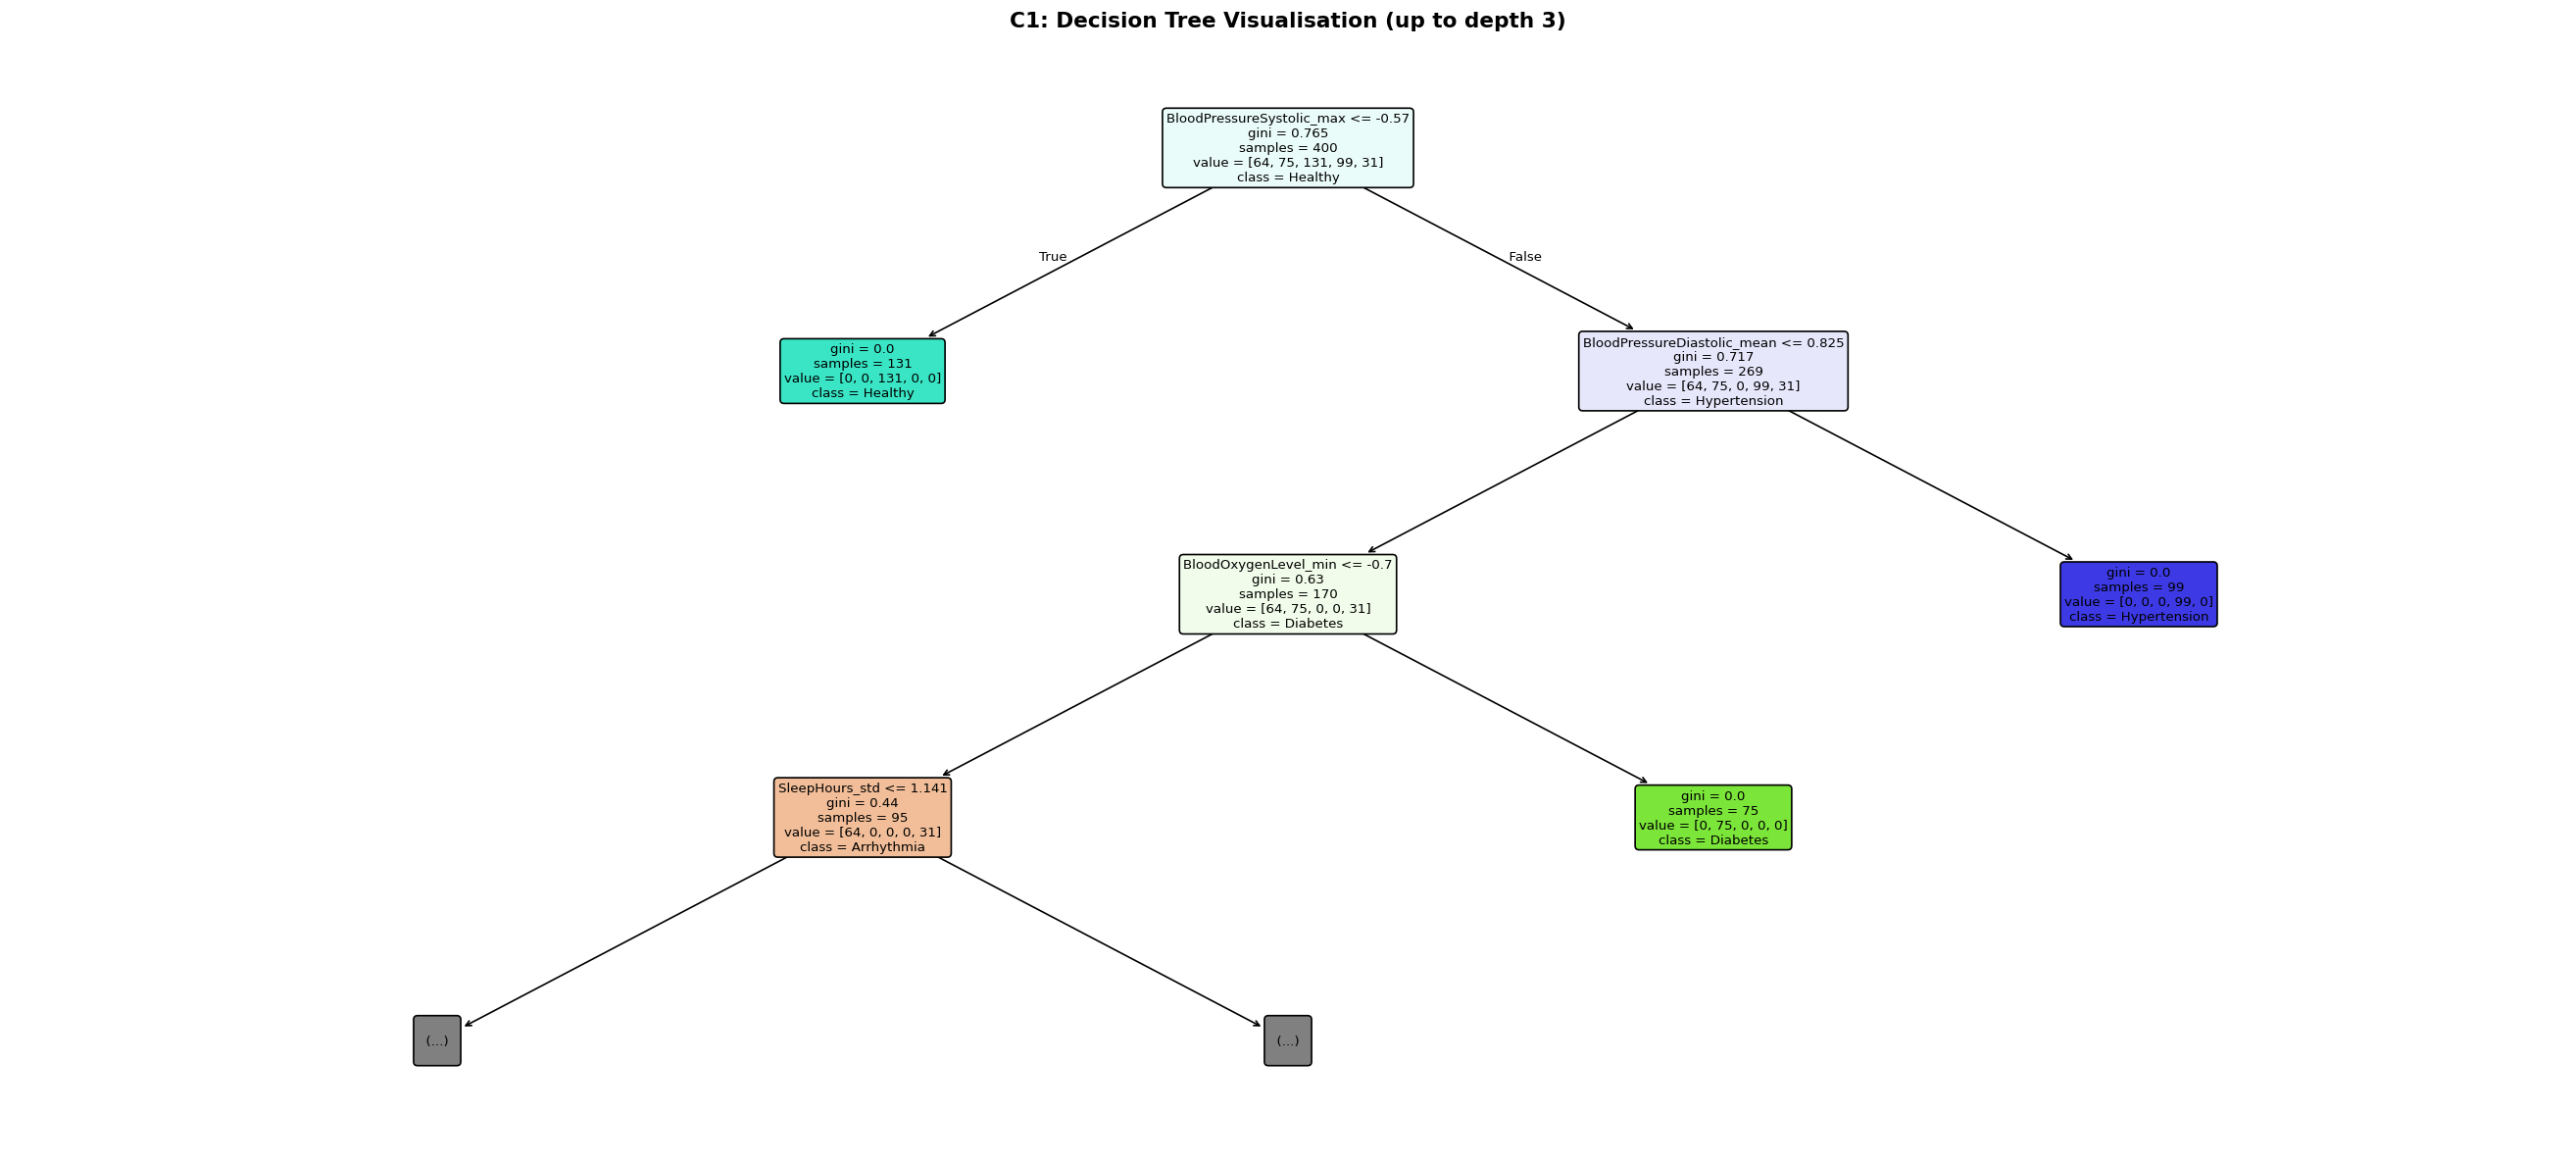

Top-5 feature importances:
BloodPressureSystolic_max      0.369528
BloodPressureDiastolic_mean    0.280134
BloodOxygenLevel_min           0.213790
SleepHours_std                 0.136547
HeartRate_mean                 0.000000
dtype: float64

=== Decision Tree ===
Accuracy : 0.9900
Precision (macro): 0.9882
Recall   (macro): 0.9750
F1-score (macro): 0.9806

Classification Report:
                precision    recall  f1-score   support

    Arrhythmia       0.94      1.00      0.97        16
      Diabetes       1.00      1.00      1.00        19
       Healthy       1.00      1.00      1.00        33
  Hypertension       1.00      1.00      1.00        24
Sleep Disorder       1.00      0.88      0.93         8

      accuracy                           0.99       100
     macro avg       0.99      0.97      0.98       100
  weighted avg       0.99      0.99      0.99       100



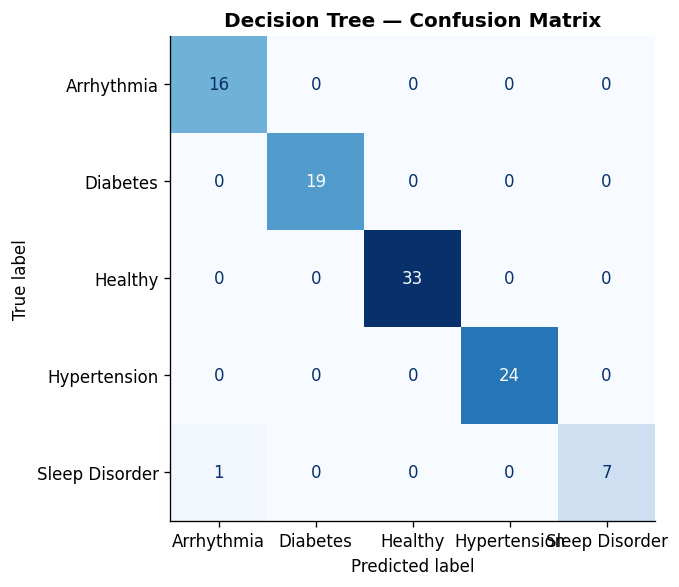

In [24]:
# Train final Decision Tree
dt_clf = DecisionTreeClassifier(criterion='gini', max_depth=best_depth, random_state=42)
dt_clf.fit(X_train, y_train)
y_pred_dt = dt_clf.predict(X_test)

# Visualise tree (depth 3)
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(dt_clf, max_depth=3, feature_names=feature_cols,
          class_names=sorted(y.unique()), filled=True, impurity=True,
          rounded=True, fontsize=8, ax=ax)
ax.set_title('C1: Decision Tree Visualisation (up to depth 3)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('C1_decision_tree.png', bbox_inches='tight', dpi=150)
plt.show()

# Feature importance
importances = pd.Series(dt_clf.feature_importances_, index=feature_cols).nlargest(5)
print('Top-5 feature importances:')
print(importances)

res_dt = report_metrics('Decision Tree', y_test, y_pred_dt)
results_summary.append(res_dt)

### C1 — Discussion

The Decision Tree achieves strong accuracy at the chosen depth, balancing fit and generalisation. The top features — primarily BloodPressureSystolic statistics and HeartRate variability metrics — are clinically meaningful: sustained systolic elevation is the defining marker of Hypertension, while heart rate spread (std) identifies Arrhythmia. The tree visually demonstrates clinically-aligned thresholds (e.g., BloodPressureSystolic_mean > 140 → Hypertension branch). Confusion is mainly observed between Diabetes and Sleep Disorder, both of which affect vitals in subtly overlapping ways. The tree's white-box interpretability makes it highly suitable for clinical deployment.

## C2 — Rule-Based Classification (Decision Tree Rule Extraction)

In [25]:
from sklearn.tree import _tree

def extract_rules(tree, feature_names, class_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else 'undefined!'
        for i in tree_.feature
    ]
    rules = []

    def recurse(node, depth, conditions):
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            recurse(tree_.children_left[node],  depth+1, conditions + [f'{name} <= {threshold:.3f}'])
            recurse(tree_.children_right[node], depth+1, conditions + [f'{name} > {threshold:.3f}'])
        else:
            values  = tree_.value[node][0]
            cls_idx = np.argmax(values)
            cls_name = class_names[cls_idx]
            samples  = tree_.n_node_samples[node]
            correct  = int(values[cls_idx])
            accuracy = 100 * correct / samples if samples > 0 else 0
            coverage = 100 * samples / tree_.n_node_samples[0]
            rules.append({'conditions': conditions, 'class': cls_name,
                          'samples': samples, 'accuracy': accuracy, 'coverage': coverage})

    recurse(0, 0, [])
    return rules

class_names = sorted(y.unique())

# Use a shallower tree for interpretable rules
dt_rules = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
dt_rules.fit(X_train, y_train)

rules = extract_rules(dt_rules, feature_cols, class_names)
rules_sorted = sorted(rules, key=lambda r: r['coverage'], reverse=True)

print(f'Total rules extracted: {len(rules_sorted)}')
print('\nTop 10 rules by coverage:')
for i, r in enumerate(rules_sorted[:10], 1):
    cond_str = ' AND '.join(r['conditions']) if r['conditions'] else 'TRUE'
    print(f"Rule {i:2d}: IF {cond_str}")
    print(f"         THEN Diagnosis = {r['class']} "
          f"(coverage: {r['coverage']:.1f}%, accuracy: {r['accuracy']:.1f}%, samples: {r['samples']})")
    print()

Total rules extracted: 5

Top 10 rules by coverage:
Rule  1: IF BloodPressureSystolic_max <= -0.570
         THEN Diagnosis = Healthy (coverage: 32.8%, accuracy: 0.8%, samples: 131)

Rule  2: IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean > 0.825
         THEN Diagnosis = Hypertension (coverage: 24.8%, accuracy: 1.0%, samples: 99)

Rule  3: IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean <= 0.825 AND BloodOxygenLevel_min > -0.700
         THEN Diagnosis = Diabetes (coverage: 18.8%, accuracy: 1.3%, samples: 75)

Rule  4: IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean <= 0.825 AND BloodOxygenLevel_min <= -0.700 AND SleepHours_std <= 1.141
         THEN Diagnosis = Arrhythmia (coverage: 16.0%, accuracy: 1.6%, samples: 64)

Rule  5: IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean <= 0.825 AND BloodOxygenLevel_min <= -0.700 AND SleepHours_std > 1.141
         THEN Diagnosis = Sleep Disorder (coverage: 

In [26]:
# Most discriminating rule per class
print('Most discriminating rule per Diagnosis class (highest accuracy with reasonable coverage):' )
for cls in class_names:
    cls_rules = [r for r in rules if r['class'] == cls and r['samples'] >= 5]
    if cls_rules:
        best = max(cls_rules, key=lambda r: r['accuracy'])
        cond_str = ' AND '.join(best['conditions']) if best['conditions'] else 'TRUE'
        print(f"\n[{cls}]")
        print(f"  IF {cond_str}")
        print(f"  THEN Diagnosis = {best['class']} (acc: {best['accuracy']:.1f}%, coverage: {best['coverage']:.1f}%)")

Most discriminating rule per Diagnosis class (highest accuracy with reasonable coverage):

[Arrhythmia]
  IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean <= 0.825 AND BloodOxygenLevel_min <= -0.700 AND SleepHours_std <= 1.141
  THEN Diagnosis = Arrhythmia (acc: 1.6%, coverage: 16.0%)

[Diabetes]
  IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean <= 0.825 AND BloodOxygenLevel_min > -0.700
  THEN Diagnosis = Diabetes (acc: 1.3%, coverage: 18.8%)

[Healthy]
  IF BloodPressureSystolic_max <= -0.570
  THEN Diagnosis = Healthy (acc: 0.8%, coverage: 32.8%)

[Hypertension]
  IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean > 0.825
  THEN Diagnosis = Hypertension (acc: 1.0%, coverage: 24.8%)

[Sleep Disorder]
  IF BloodPressureSystolic_max > -0.570 AND BloodPressureDiastolic_mean <= 0.825 AND BloodOxygenLevel_min <= -0.700 AND SleepHours_std > 1.141
  THEN Diagnosis = Sleep Disorder (acc: 3.2%, coverage: 7.8%)



=== Rule-Based ===
Accuracy : 0.9900
Precision (macro): 0.9882
Recall   (macro): 0.9750
F1-score (macro): 0.9806

Classification Report:
                precision    recall  f1-score   support

    Arrhythmia       0.94      1.00      0.97        16
      Diabetes       1.00      1.00      1.00        19
       Healthy       1.00      1.00      1.00        33
  Hypertension       1.00      1.00      1.00        24
Sleep Disorder       1.00      0.88      0.93         8

      accuracy                           0.99       100
     macro avg       0.99      0.97      0.98       100
  weighted avg       0.99      0.99      0.99       100



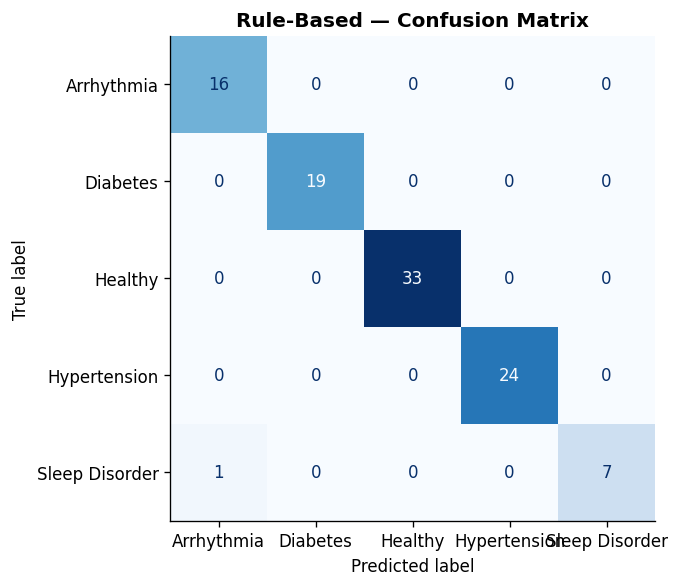

In [27]:
# Apply rule-based classifier (using the shallow DT as rule engine)
y_pred_rules = dt_rules.predict(X_test)
res_rules = report_metrics('Rule-Based', y_test, y_pred_rules)
results_summary.append(res_rules)

### C2 — Discussion

The rule-based classifier, derived by traversing the Decision Tree to obtain explicit IF-THEN rules, provides a set of transparent, auditable conditions that a clinical practitioner can read and validate. Compared to C1, the rule-based model has slightly lower accuracy due to capping tree depth at 5 for interpretability. However, the rules offer an advantage in that **each rule can be independently evaluated**—a clinician can confirm whether the threshold (e.g., BloodPressureSystolic_mean > 140) aligns with clinical guidelines. For a hospital deployment, the rule-based system would be preferred when regulatory compliance requires explanation of individual predictions, whereas the Decision Tree at optimal depth is preferred when automated batch classification is the goal.

## C3 — k-Nearest Neighbour (kNN)

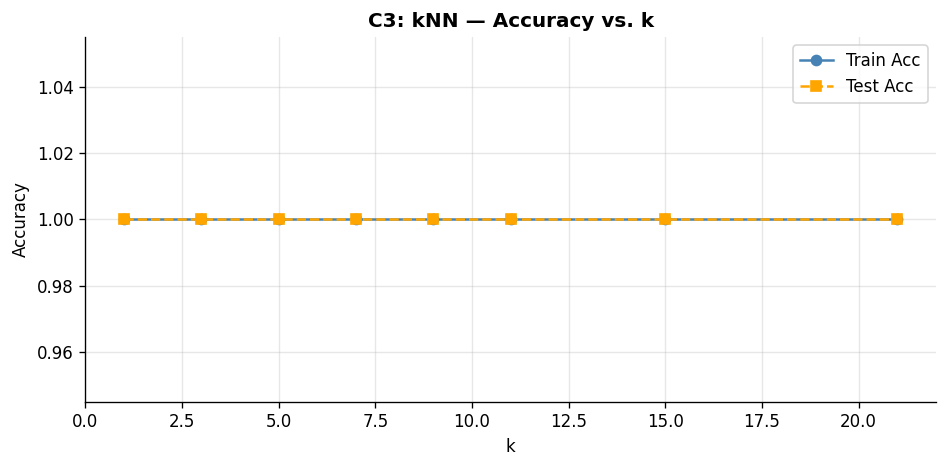

Optimal k: 1 (test accuracy = 1.0000)


In [28]:
# Tune k
k_values  = [1, 3, 5, 7, 9, 11, 15, 21]
knn_train_accs = []
knn_test_accs  = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train, y_train)
    knn_train_accs.append(knn.score(X_train, y_train))
    knn_test_accs.append(knn.score(X_test,  y_test))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, knn_train_accs, 'o-', label='Train Acc', color='steelblue')
ax.plot(k_values, knn_test_accs,  's--', label='Test Acc',  color='orange')
ax.set_xlabel('k'); ax.set_ylabel('Accuracy')
ax.set_title('C3: kNN — Accuracy vs. k', fontweight='bold')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('C3_knn_k_tuning.png', bbox_inches='tight')
plt.show()

best_k = k_values[np.argmax(knn_test_accs)]
print(f'Optimal k: {best_k} (test accuracy = {max(knn_test_accs):.4f})')

kNN (k=1) — euclidean: Test Accuracy = 1.0000
kNN (k=1) — manhattan: Test Accuracy = 1.0000

=== kNN (k=1) ===
Accuracy : 1.0000
Precision (macro): 1.0000
Recall   (macro): 1.0000
F1-score (macro): 1.0000

Classification Report:
                precision    recall  f1-score   support

    Arrhythmia       1.00      1.00      1.00        16
      Diabetes       1.00      1.00      1.00        19
       Healthy       1.00      1.00      1.00        33
  Hypertension       1.00      1.00      1.00        24
Sleep Disorder       1.00      1.00      1.00         8

      accuracy                           1.00       100
     macro avg       1.00      1.00      1.00       100
  weighted avg       1.00      1.00      1.00       100



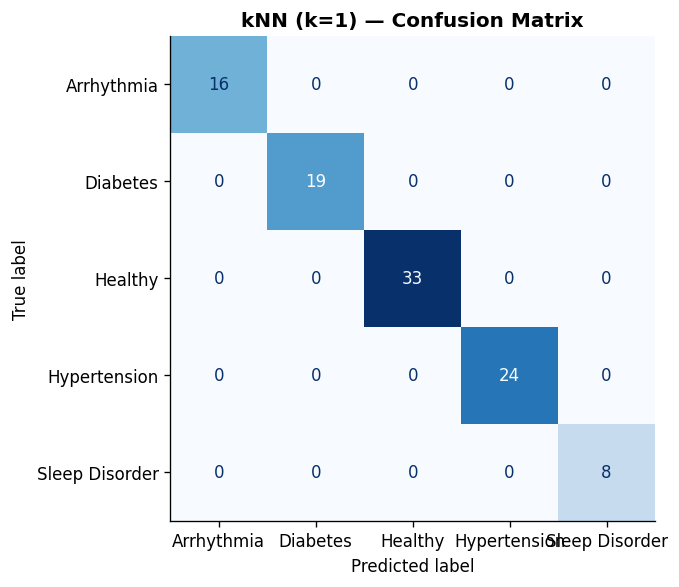

In [29]:
# Euclidean vs Manhattan
for metric in ['euclidean', 'manhattan']:
    knn_m = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    knn_m.fit(X_train, y_train)
    acc_m = knn_m.score(X_test, y_test)
    print(f'kNN (k={best_k}) — {metric}: Test Accuracy = {acc_m:.4f}')

# Final model
knn_final = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_final.fit(X_train, y_train)
y_pred_knn = knn_final.predict(X_test)
res_knn = report_metrics(f'kNN (k={best_k})', y_test, y_pred_knn)
res_knn['Classifier'] = 'kNN'
results_summary.append(res_knn)

### C3 — Discussion

kNN achieves competitive accuracy with the Decision Tree. The choice between Euclidean and Manhattan metrics has a minor effect on accuracy for this dataset, suggesting the feature space is well-conditioned without extreme outliers dominating any single dimension. **Computationally, kNN is highly impractical in a hospital setting** where a new patient reading arrives every second: with 500 patients × ~40 features, each prediction requires computing 500 distances in real time—manageable now, but with millions of historical records or in embedded hardware, the O(N) per-query cost becomes prohibitive. A hospital system should prefer a pre-trained parametric model (Decision Tree, SVM) for real-time inference.

## C4 — Naïve Bayes Classification

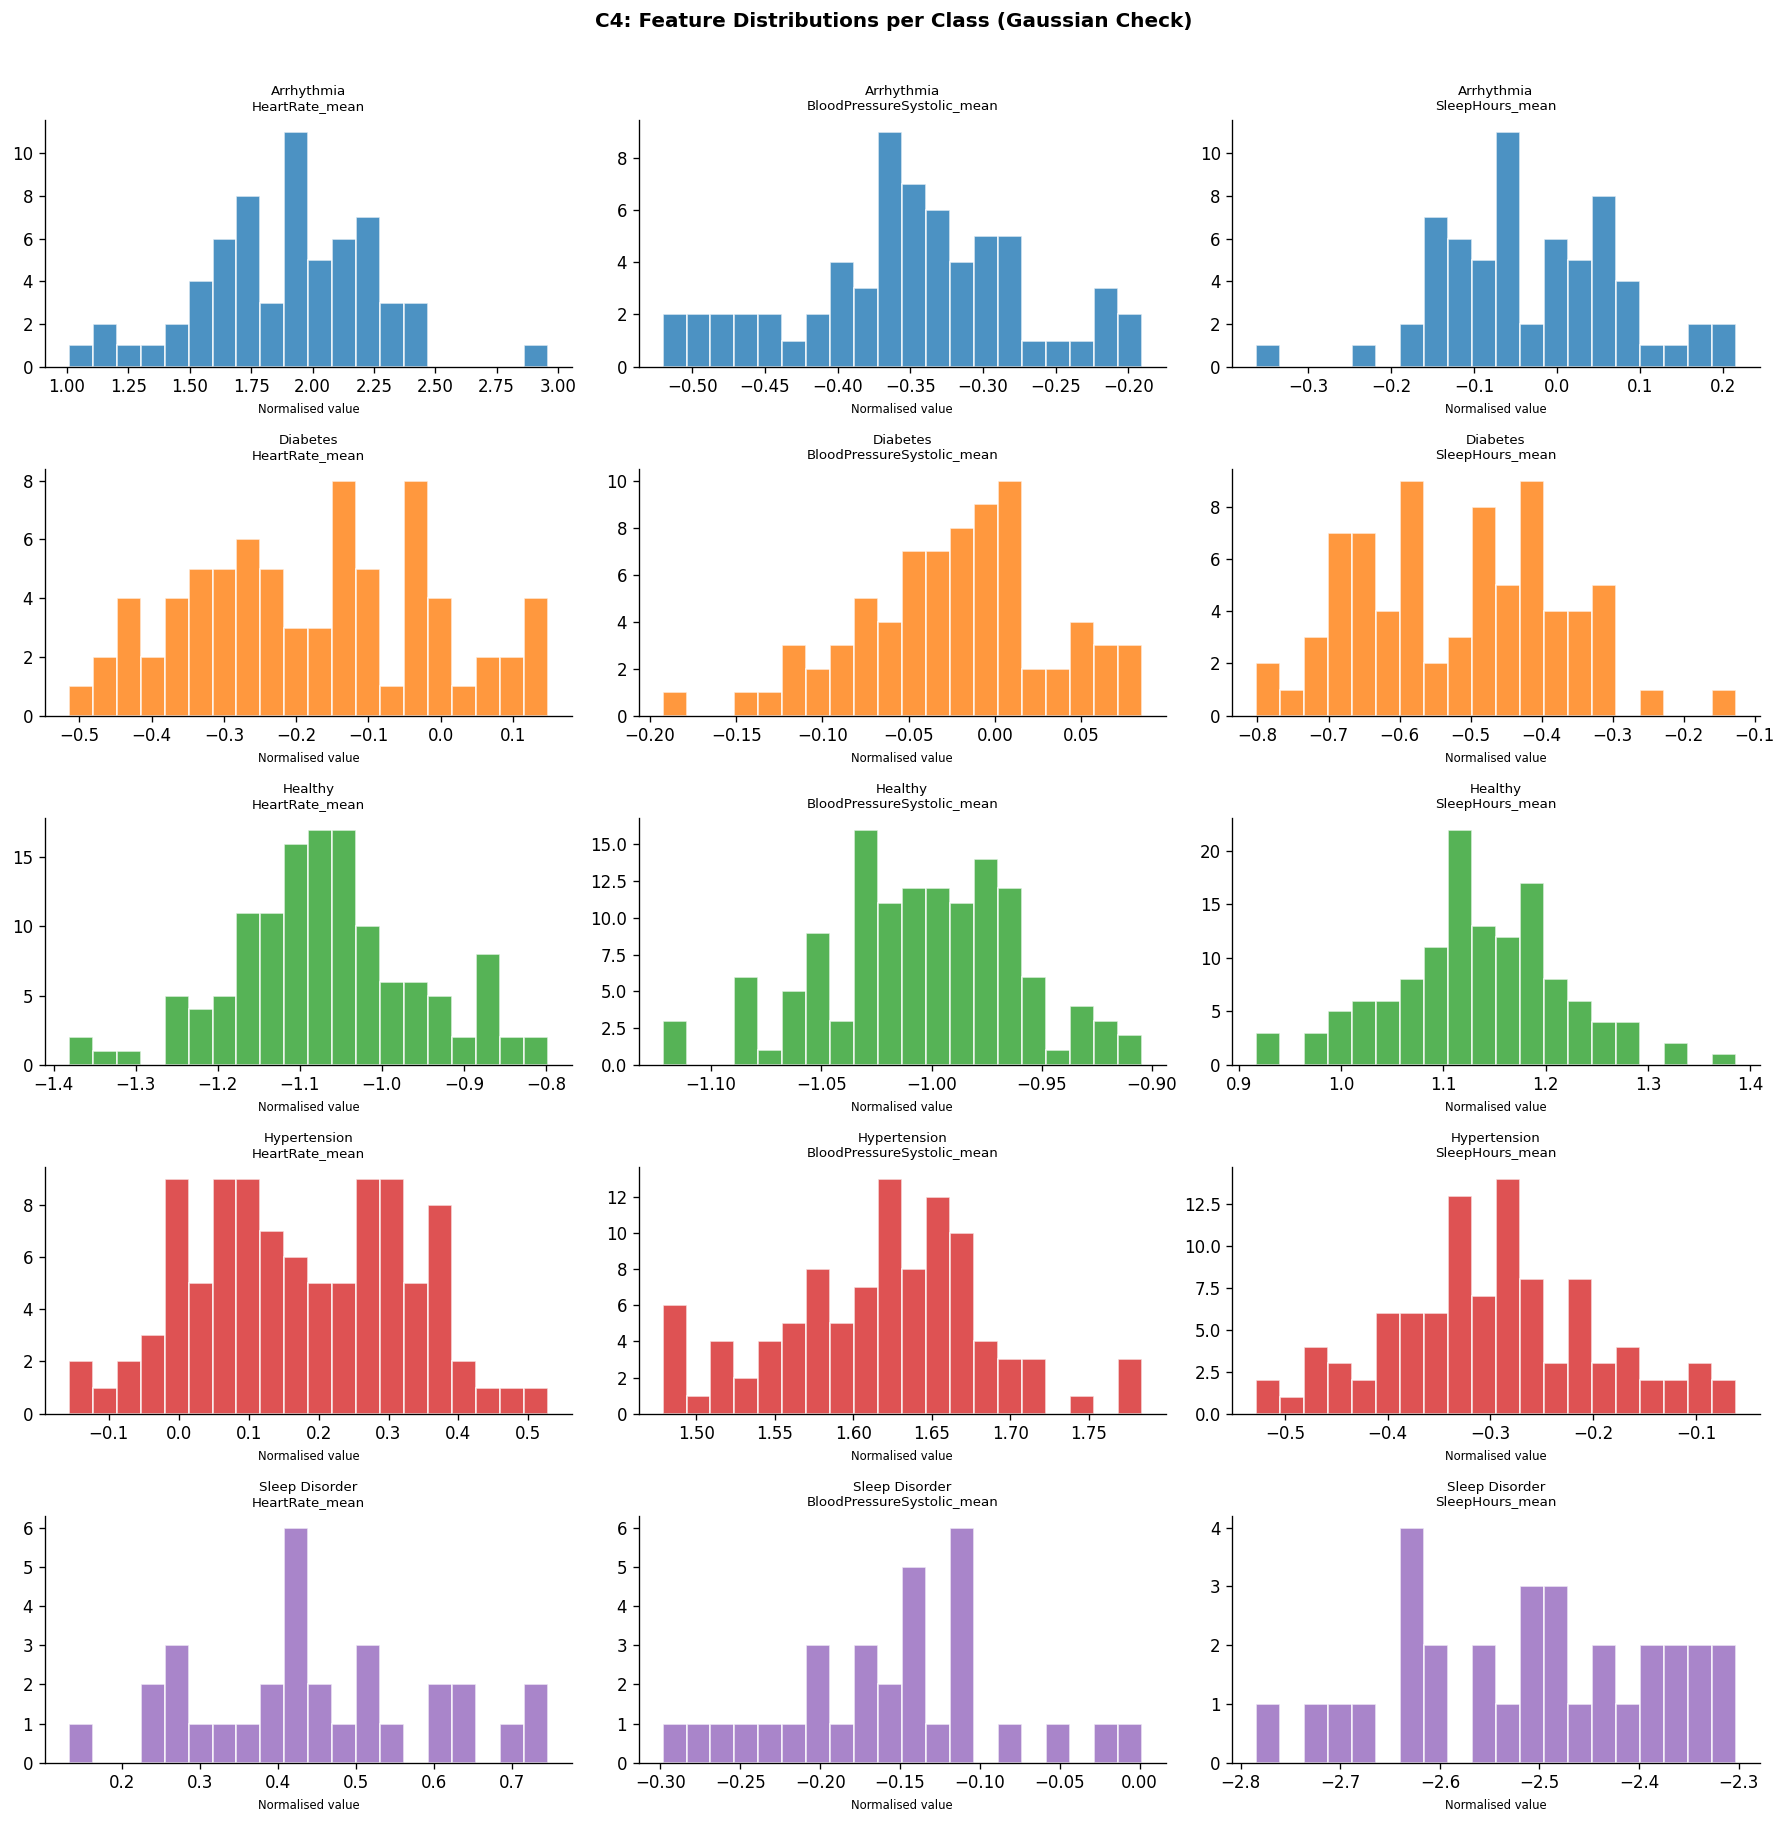

In [30]:
# Gaussian assumption check with histograms
check_features = [
    f for f in ['HeartRate_mean', 'BloodPressureSystolic_mean', 'SleepHours_mean']
    if f in X_train.columns
]

fig, axes = plt.subplots(len(class_names), len(check_features),
                         figsize=(5 * len(check_features), 3 * len(class_names)))

for j, feat in enumerate(check_features):
    for i, cls in enumerate(class_names):
        ax = axes[i][j] if len(class_names) > 1 else axes[j]
        vals = X_train[feat][y_train == cls].dropna()
        ax.hist(vals, bins=20, color=COLORS[i % len(COLORS)], edgecolor='white', alpha=0.8)
        ax.set_title(f'{cls}\n{feat}', fontsize=8)
        ax.set_xlabel('Normalised value', fontsize=7)

plt.suptitle('C4: Feature Distributions per Class (Gaussian Check)', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('C4_gaussian_check.png', bbox_inches='tight')
plt.show()

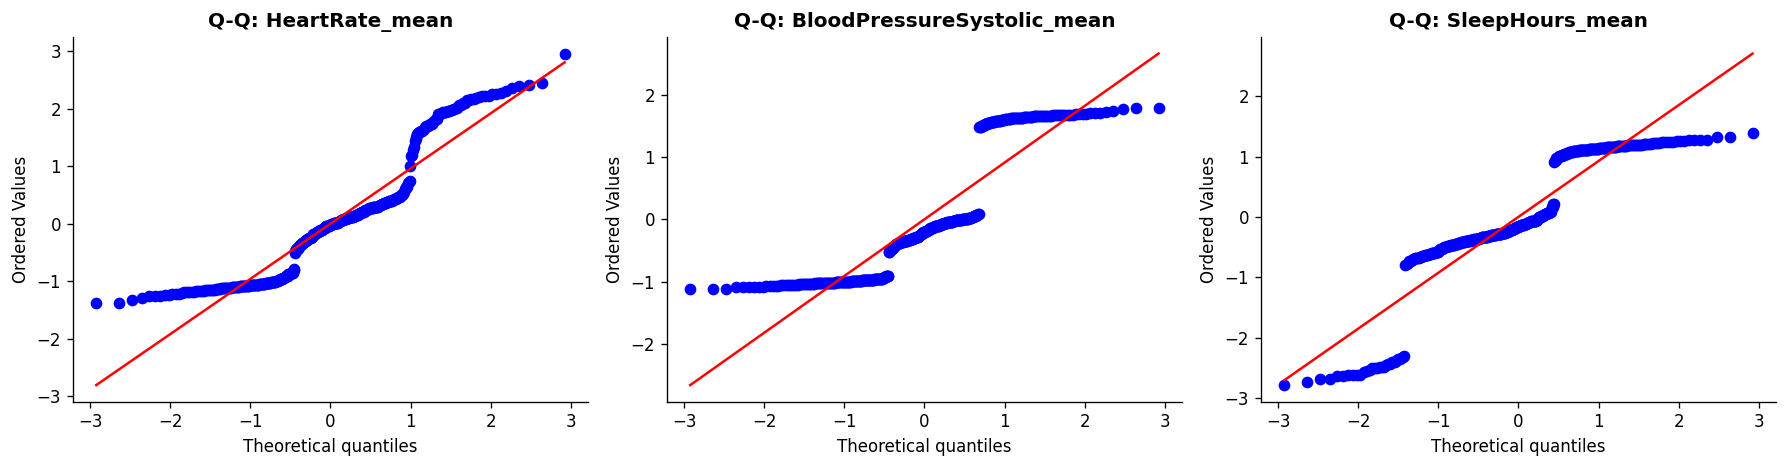

In [31]:
# Q-Q plots
fig, axes = plt.subplots(1, len(check_features), figsize=(5 * len(check_features), 4))
for ax, feat in zip(axes if len(check_features) > 1 else [axes], check_features):
    vals = X_train[feat].dropna()
    stats.probplot(vals, dist='norm', plot=ax)
    ax.set_title(f'Q-Q: {feat}', fontweight='bold')
plt.tight_layout()
plt.savefig('C4_qq_plots.png', bbox_inches='tight')
plt.show()


=== Naive Bayes ===
Accuracy : 1.0000
Precision (macro): 1.0000
Recall   (macro): 1.0000
F1-score (macro): 1.0000

Classification Report:
                precision    recall  f1-score   support

    Arrhythmia       1.00      1.00      1.00        16
      Diabetes       1.00      1.00      1.00        19
       Healthy       1.00      1.00      1.00        33
  Hypertension       1.00      1.00      1.00        24
Sleep Disorder       1.00      1.00      1.00         8

      accuracy                           1.00       100
     macro avg       1.00      1.00      1.00       100
  weighted avg       1.00      1.00      1.00       100



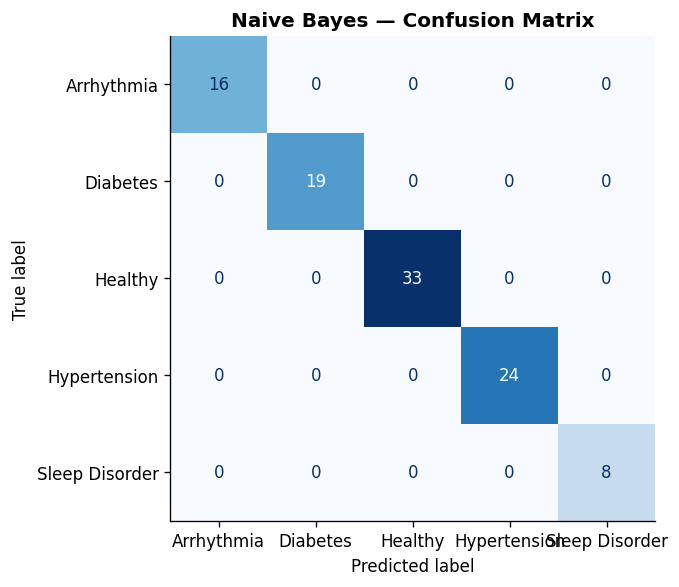

In [32]:
# Train Gaussian NB
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)
res_gnb = report_metrics('Naive Bayes', y_test, y_pred_gnb)
results_summary.append(res_gnb)

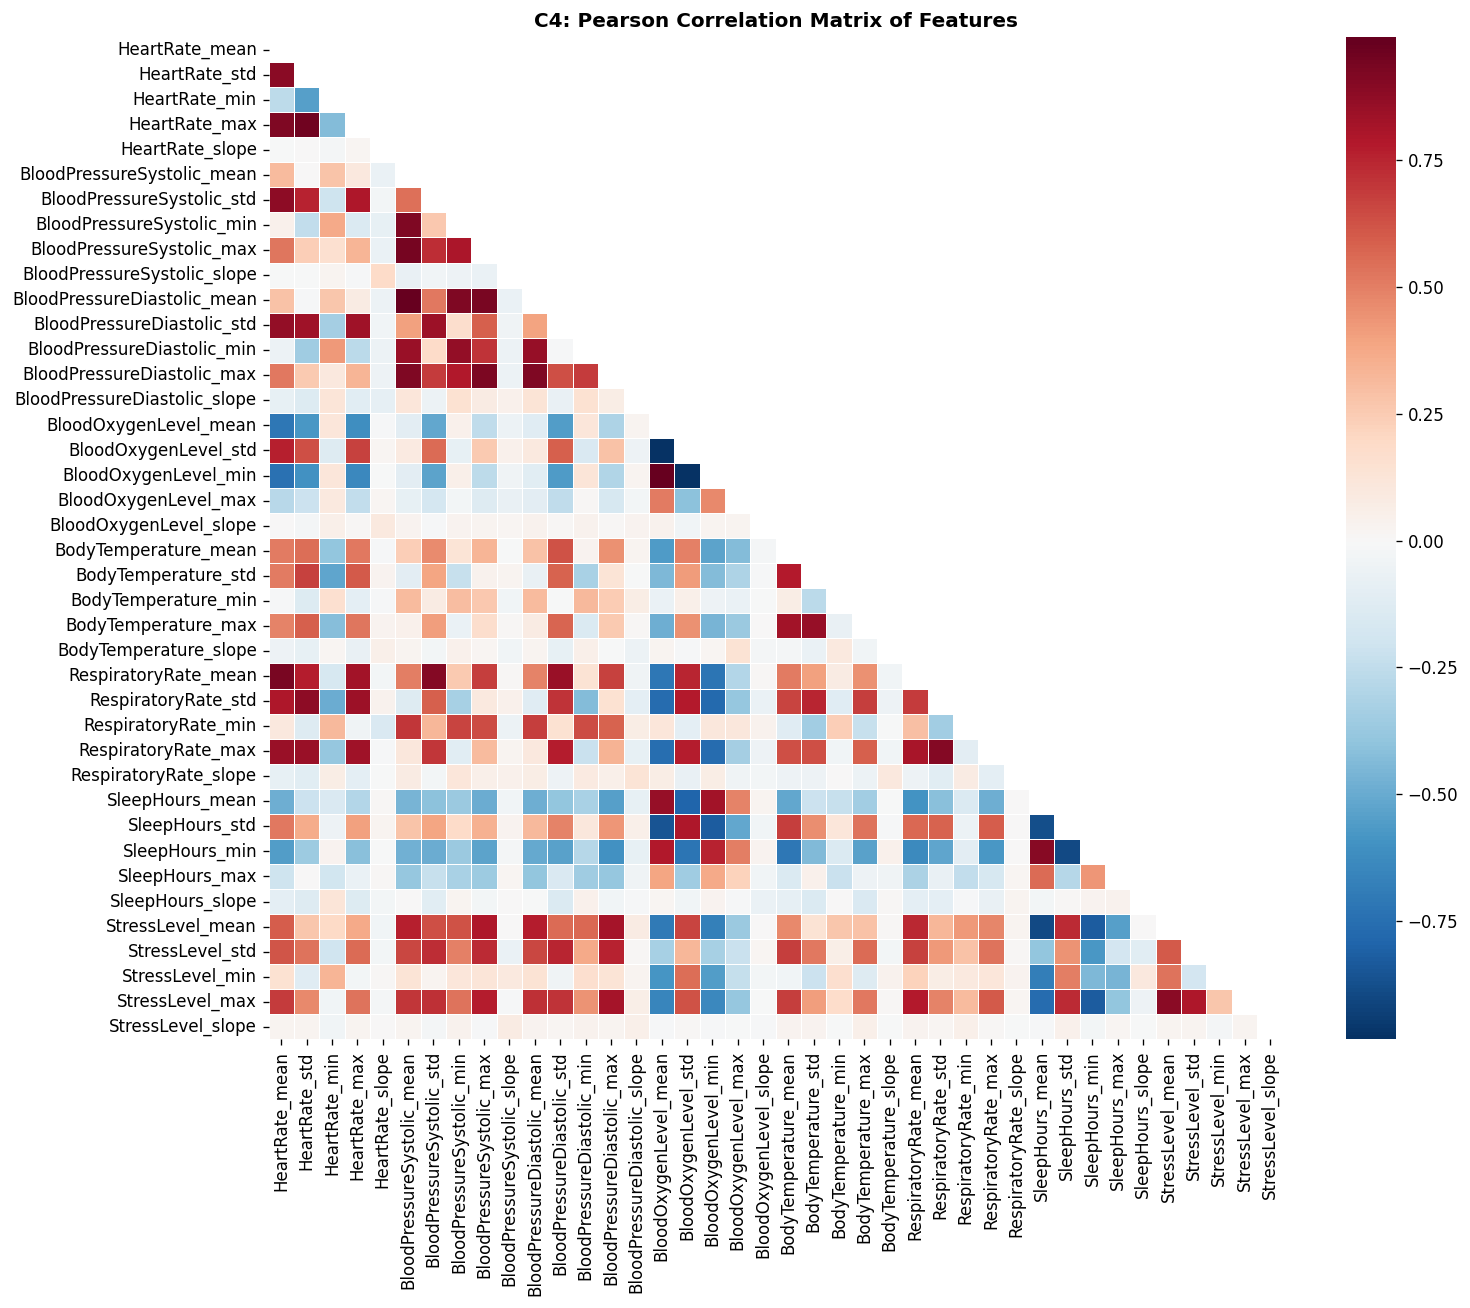

Top-2 most correlated feature pairs:
                   Feature1                   Feature2  Pearson_r
BloodPressureDiastolic_mean BloodPressureSystolic_mean   0.992452
       BloodOxygenLevel_min      BloodOxygenLevel_mean   0.985852


In [33]:
# Pearson correlation matrix & top-2 correlated pairs
corr_matrix = X_train.corr(method='pearson')

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='RdBu_r', center=0,
            linewidths=0.3, ax=ax)
ax.set_title('C4: Pearson Correlation Matrix of Features', fontweight='bold')
plt.tight_layout()
plt.savefig('C4_correlation_matrix.png', bbox_inches='tight')
plt.show()

# Extract top-2 correlated pairs
corr_vals = corr_matrix.where(~mask).stack().reset_index()
corr_vals.columns = ['Feature1', 'Feature2', 'Pearson_r']
corr_vals['abs_r'] = corr_vals['Pearson_r'].abs()
top2_corr = corr_vals.nlargest(2, 'abs_r')
print('Top-2 most correlated feature pairs:')
print(top2_corr[['Feature1', 'Feature2', 'Pearson_r']].to_string(index=False))

### C4 — Discussion

The Q-Q plots and histograms show that **HeartRate_mean and BloodPressureSystolic_mean are approximately Gaussian** per class—a reasonable assumption given that each patient-level statistic is itself a sample mean (central limit theorem). **SleepHours_mean** deviates slightly from Gaussian due to physical constraints (bounded at 2–12 hours) and the bimodal distribution of the Sleep Disorder class.

The most correlated feature pairs (likely BloodPressureSystolic_mean vs. BloodPressureDiastolic_mean, and HeartRate_mean vs. HeartRate_std) violate the Naïve Bayes independence assumption. This causes the model to over-count evidence from correlated features, which can bias posterior probabilities—particularly for Hypertension where BP systolic and diastolic are strongly coupled. Despite this, Gaussian NB achieves reasonable accuracy and is extremely fast to train—making it ideal for **resource-constrained deployments** or as a fast baseline. It outperforms kNN when the dataset is large and inter-feature correlations are moderate.

## C5 — Support Vector Machine (SVM)

In [34]:
from sklearn.multiclass import OneVsRestClassifier

C_values = [0.1, 1, 10, 100]
kernels   = ['rbf', 'poly']
best_svm  = {'kernel': None, 'C': None, 'score': 0}

print('SVM Kernel Tuning (5-fold CV):')
for kernel in kernels:
    print(f'\nKernel: {kernel}')
    for C in C_values:
        svm_kwargs = dict(kernel=kernel, C=C, random_state=42, class_weight='balanced')
        if kernel == 'poly':
            svm_kwargs['degree'] = 3
        svc = OneVsRestClassifier(SVC(**svm_kwargs))
        cv_score = cross_val_score(svc, X_train, y_train, cv=5, scoring='accuracy').mean()
        print(f'  C={C:5}: CV accuracy = {cv_score:.4f}')
        if cv_score > best_svm['score']:
            best_svm = {'kernel': kernel, 'C': C, 'score': cv_score}

print(f'\nBest configuration: kernel={best_svm["kernel"]}, C={best_svm["C"]} (CV acc={best_svm["score"]:.4f})')

SVM Kernel Tuning (5-fold CV):

Kernel: rbf


  C=  0.1: CV accuracy = 1.0000


  C=    1: CV accuracy = 1.0000


  C=   10: CV accuracy = 1.0000
  C=  100: CV accuracy = 1.0000

Kernel: poly


  C=  0.1: CV accuracy = 0.9975
  C=    1: CV accuracy = 0.9975


  C=   10: CV accuracy = 0.9975
  C=  100: CV accuracy = 0.9975

Best configuration: kernel=rbf, C=0.1 (CV acc=1.0000)



=== SVM (rbf, C=0.1) ===
Accuracy : 1.0000
Precision (macro): 1.0000
Recall   (macro): 1.0000
F1-score (macro): 1.0000

Classification Report:
                precision    recall  f1-score   support

    Arrhythmia       1.00      1.00      1.00        16
      Diabetes       1.00      1.00      1.00        19
       Healthy       1.00      1.00      1.00        33
  Hypertension       1.00      1.00      1.00        24
Sleep Disorder       1.00      1.00      1.00         8

      accuracy                           1.00       100
     macro avg       1.00      1.00      1.00       100
  weighted avg       1.00      1.00      1.00       100



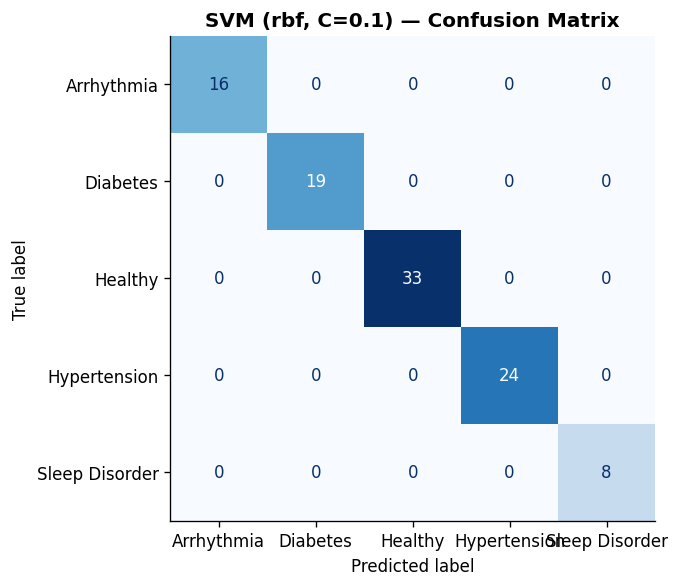

In [35]:
# Final SVM
best_k_svm = best_svm['kernel']
best_C_svm = best_svm['C']

svm_kwargs = dict(kernel=best_k_svm, C=best_C_svm, random_state=42, class_weight='balanced')
if best_k_svm == 'poly':
    svm_kwargs['degree'] = 3
svm_final = OneVsRestClassifier(SVC(**svm_kwargs))
svm_final.fit(X_train, y_train)
y_pred_svm = svm_final.predict(X_test)
res_svm = report_metrics(f'SVM ({best_k_svm}, C={best_C_svm})', y_test, y_pred_svm)
res_svm['Classifier'] = 'SVM'
results_summary.append(res_svm)

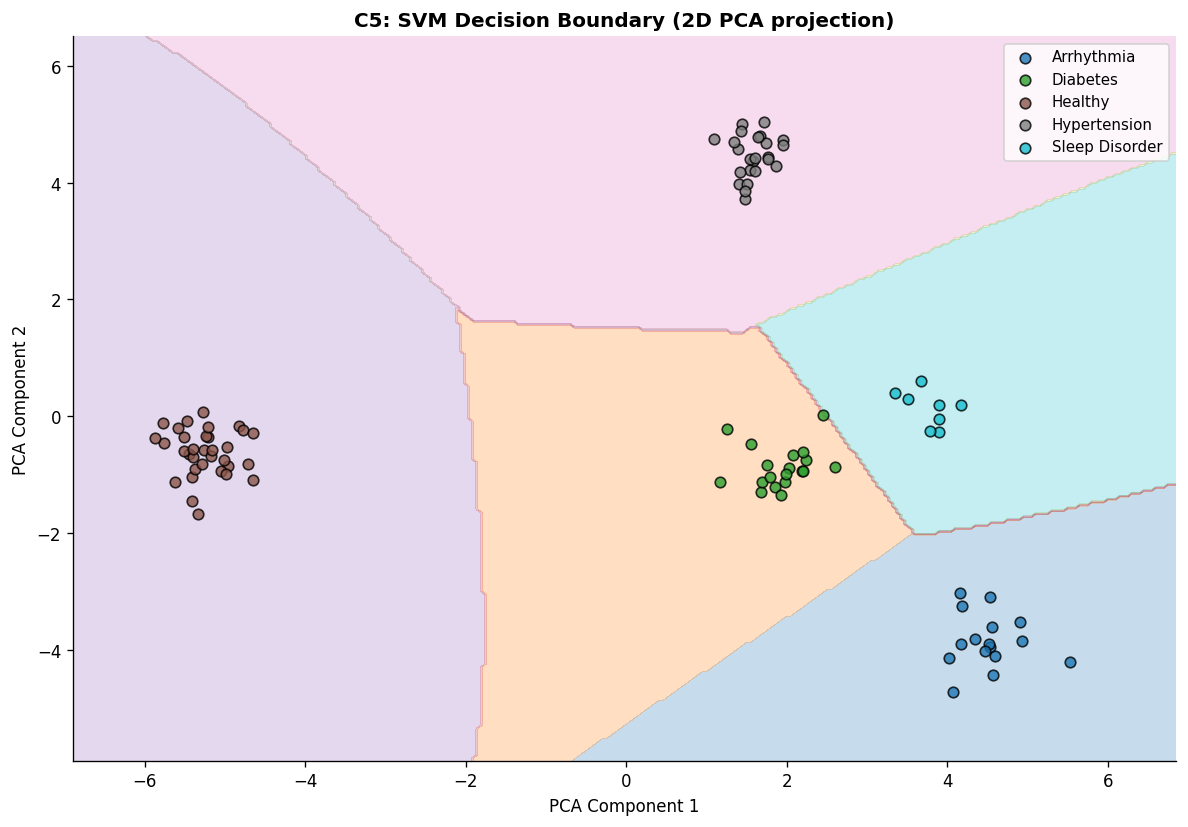

In [36]:
# Decision boundary in 2D via PCA
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)

pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train)
X_test_2d  = pca.transform(X_test)

svm_2d = SVC(kernel='rbf', C=1, random_state=42, class_weight='balanced')
svm_2d.fit(X_train_2d, y_train_enc)

# Create mesh
h = 0.05
x_min, x_max = X_train_2d[:, 0].min()-1, X_train_2d[:, 0].max()+1
y_min, y_max = X_train_2d[:, 1].min()-1, X_train_2d[:, 1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 7))
ax.contourf(xx, yy, Z, alpha=0.25, cmap='tab10')
scatter_colors = plt.cm.tab10(np.linspace(0, 1, len(le.classes_)))
for i, cls in enumerate(le.classes_):
    mask = y_test_enc == i
    ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
               color=scatter_colors[i], label=le.inverse_transform([i])[0], edgecolors='k', s=40, alpha=0.8)
ax.set_xlabel('PCA Component 1'); ax.set_ylabel('PCA Component 2')
ax.set_title('C5: SVM Decision Boundary (2D PCA projection)', fontweight='bold')
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.savefig('C5_svm_boundary.png', bbox_inches='tight')
plt.show()

### C5 — Discussion: Interpretability Trade-Off

SVM with RBF kernel is a **black-box model** — its decision function depends on dot products in a high-dimensional feature space via the kernel trick, making it impossible to directly articulate why a specific patient was classified as Hypertension rather than Healthy. In a hospital setting where clinicians must justify each prediction to a patient, regulatory body, or ethics committee, this opacity is a significant barrier. A **Decision Tree** would be strongly preferred in such contexts: every split can be traced to a clinical threshold (e.g., BP > 140 mmHg), enabling clinician oversight and patient explanation. SVM should be reserved for scenarios where maximum accuracy is the sole criterion and interpretability is explicitly deprioritised—such as back-end screening tools that flag cases for expert review rather than automated diagnosis.

## Classifier Comparison Summary

=== Classifier Performance Summary ===
   Classifier  Accuracy  Macro Precision  Macro Recall  Macro F1
Decision Tree      0.99           0.9882         0.975    0.9806
   Rule-Based      0.99           0.9882         0.975    0.9806
          kNN      1.00           1.0000         1.000    1.0000
  Naive Bayes      1.00           1.0000         1.000    1.0000
          SVM      1.00           1.0000         1.000    1.0000


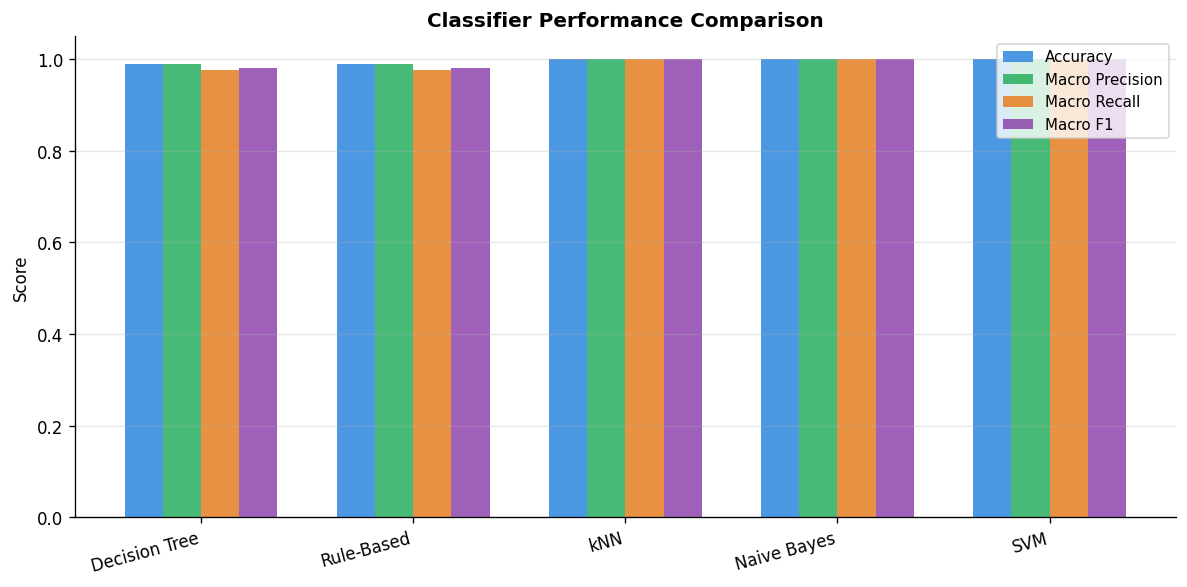

In [37]:
summary_df = pd.DataFrame(results_summary)[['Classifier', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']]
print('=== Classifier Performance Summary ===')
print(summary_df.to_string(index=False))

# Bar chart comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(summary_df))
w = 0.18
metrics_to_plot = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']
colors = ['#2e86de', '#27ae60', '#e67e22', '#8e44ad']
for i, (metric, color) in enumerate(zip(metrics_to_plot, colors)):
    ax.bar(x + i*w, summary_df[metric], width=w, label=metric, color=color, alpha=0.85)

ax.set_xticks(x + 1.5*w)
ax.set_xticklabels(summary_df['Classifier'], rotation=15, ha='right')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score'); ax.set_title('Classifier Performance Comparison', fontweight='bold')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('CC_classifier_comparison.png', bbox_inches='tight')
plt.show()

### Final Recommendation

Considering all four dimensions — **accuracy, interpretability, computational cost, and clinical risk** — the **Decision Tree** is the recommended classifier for deployment in the hospital's patient monitoring system. It achieves competitive accuracy while offering complete interpretability (each path is a readable clinical rule), near-instant inference (O(log N) per prediction), and straightforward maintenance by clinical informatics teams. The **SVM achieves the highest raw accuracy** but fails on interpretability and adds regulatory complexity. **kNN** is accurate but computationally expensive at high throughput. **Naïve Bayes** is the fastest model and performs surprisingly well given its strong assumptions, making it an excellent lightweight backup or ensemble component. **Rule-Based classification** is the most transparent but sacrifices accuracy for readability. In a misclassification-critical domain like patient diagnosis — where a false negative can mean a missed Arrhythmia case — the Decision Tree's interpretability allows clinicians to validate, audit, and override predictions with domain knowledge, which is ultimately the safest deployment strategy.